# Cross-model distillation: student-hyperparameter exploration — results

Documents the July 21–24 2026 **student-HP exploration for cross-initialization (cross-model) distillation** of the dog trait: the teacher is the original `pythia-160m` (tseed1, `ex10-20_prefix_n100k` numbers), students are the PolyPythia re-seeds `data-seed1` / `weight-seed2` (§10 adds `weight-seed1`), and — unlike the cross-seed notebook, which fixes the student recipe — here the **student hyperparameters are the treatment**. Motivating question: cross-init transfer at the standard student recipe is weak (~0.02–0.15 test p(target) at ep20). Can a stronger student surface more of it?

**The experiment ladder** (each stage decided from the previous one's results; job lists in `run_logs/dog_crossdistill_studenthp_*_jobs.txt`, `run_logs/dog_studenthp_ds1_*_jobs.txt` and `run_logs/hp_t*_jobs.txt`, workers/launchers `run_logs/dog_crossdistill_studenthp_{worker.py,launcher.sh}`):

1. **Variant probe** (36 jobs, ep20): top-6 teacher configs by cross-init transfer × both cross bases × {lr 5e-4 · r8α32, lr 1e-4 · r16α64, lr 5e-4 · r16α64}.
2. **Dose check** (24 + 2 jobs): the two single-change variants at ep10; then lr 5e-4 at ep5 for the strongest config.
3. **Neighborhood grid** (33 jobs, focus cell `ep2_lr5e-4_r32a64 → data-seed1`): lr {1e-4, 2e-4, 3e-4} × LoRA {r8α32, r16α32, r8α64} × ep {5, 10, 20}, plus first seed replicates.
4. **Frontier at 3 seeds** (24 jobs, ep20): the surviving gentle region — {r8α16, r16α16, r16α32, r32α32, r32α64, r64α64} at lr 1e-4 and {r8α32, r16α32, r32α32} at lr 5e-5.
5. **ep40 dose rung** (6 jobs): winner (r16α32) and baseline (r8α32) × seeds 1–3.
6. **lr × α control** (21 + 3 jobs, 3 seeds; §8): lr 2e-4 at *small* α {r8α8, r8α16, r16α16} × {ep5, ep20}, plus the r8α64 lr-rescue (lr 5e-4 vs 5e-5) — breaks the lr-2e-4 / α confound.
7. **Cross-teacher menu replication** (7 × 30 jobs, 3 seeds; §10): the std recipe + the four §8 gentle recipes × {ep5, ep20} on seven more teacher lineages across three bases, incl. the new base `weight-seed1` (`run_logs/hp_t{2..8}_*_jobs.txt`).

**Headline findings** (verified below against the live artifacts): the aggression cliff is the **product lr × α** (raw LoRA update magnitude), not lr alone — cells die at lr×α ≳ 1e-2 and survive below ~3e-3 (§8). This *revises* the earlier "lr ≥ 2e-4 is an absolute dead zone" reading, which was confounded by scale: lr 2e-4 at small α is in fact excellent (r8α16 ep20 = **0.120**, the top cell of the whole exploration), while the same lr at α ≥ 32 collapses to < 0.001. The r8α64 lr-rescue is the clean within-architecture proof (0.000 → 0.096 by lr 5e-4 → 5e-5). Beyond that, **more capacity at gentle scale** helps modestly ("slow and wide": r16α32 ep20 seed-1 0.168, mean 0.099 — within noise of baseline 0.121), **dose (epochs) reliably pays** (ep20 ≫ ep5), and **seed spread is large** (baseline ep20 seeds 0.039–0.171; r8α16 spans 0.002–0.240), so single-seed contrasts under ~±0.06 are noise. **§10 then replicates the gentle menu on seven more teacher lineages: safe everywhere (69/70 cells alive) but better nowhere (max gain over std +0.017, inside noise) — the standard recipe stays the cross-init default.**

> **Live notebook.** Sections self-filter to artifacts present on disk; frontier/ep40/§8 cells appear as their sweeps drain. Single-seed cells carry no uncertainty; seed-replicated cells show per-seed points.

## Setup and per-seed artifact loader

Loads every student cell under the six top teacher lineages × both cross bases (plain `ex10-20_prefix_n100k` template): the seed-averaged `preference_summary.json` per cell **and** each `ftseed{N}/preference_eval.json` for per-seed test values — seed spread is a first-class object here. `runs` = one row per (cell, seed); `cells` = one row per cell with mean + seed tuple.

In [1]:
from __future__ import annotations
import json, re
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from subliminal_learning.analysis.setup import bootstrap, set_plot_style

ROOT, OUTPUT_ROOT = bootstrap()
STUDENTS_ROOT = OUTPUT_ROOT / "students"

ANIMAL, NBASE, TSEED, DATASET = "dog", "pythia-160m", 1, "ex10-20_prefix_n100k"
BASES = ["pythia-160m-data-seed1", "pythia-160m-weight-seed2"]
BASE_LABEL = {"pythia-160m-data-seed1": "data-seed1", "pythia-160m-weight-seed2": "weight-seed2"}
# The exploration's focus cell: the teacher config x student base with the strongest baseline transfer.
FOCUS_TEACHER, FOCUS_BASE = "ep2_lr5e-4_r32a64", "pythia-160m-data-seed1"
BASELINE_LR, BASELINE_LORA = 1e-4, (8, 32)   # the standard student recipe (Blank et al. port)

# Top-6 teacher tags by mean cross-init test at student ep20 (the variant-probe manifest, kept in run_logs).
TOP6_MANIFEST = ROOT / "run_logs/dog_crossdistill_top6_configs.json"
TOP6 = list(json.loads(TOP6_MANIFEST.read_text())["param_tags"]) if TOP6_MANIFEST.exists() else []
assert TOP6, "top-6 manifest missing"

STUDENT_TAG_RE = re.compile(r"^ep(?P<ep>\d+)_lr(?P<lr>[^_]+)_r(?P<r>\d+)a(?P<a>\d+)$")
set_plot_style(dpi=115, hide_spines=True)
print("output_root:", OUTPUT_ROOT); print("top-6 teachers:", TOP6)

output_root: /mnt/ssd-2/soar-subliminal/angela/outputs
top-6 teachers: ['ep2_lr5e-4_r32a64', 'ep2_lr5e-4_r16a64', 'ep7_lr2e-4_r8a32', 'ep20_lr2e-4_r8a8', 'ep20_lr1e-4_r32a32', 'ep20_lr1e-4_r8a32']


In [2]:
def read(p): return json.loads(Path(p).read_text())

def load():
    run_rows, cell_rows = [], []
    for base in BASES:
        for tag in TOP6:
            lin = STUDENTS_ROOT / ANIMAL / base / f"from_{tag}_tseed{TSEED}_nbase-{NBASE}" / DATASET
            if not lin.exists(): continue
            for cd in sorted(lin.iterdir()):
                m = STUDENT_TAG_RE.fullmatch(cd.name)
                if not m or not (cd / "preference_summary.json").exists(): continue
                doc = read(cd / "preference_summary.json")
                mean_test = next((s["p_target_mean"] for s in doc.get("summaries", [])
                                  if s["prompt_set"] == "test"), None)
                seeds = {}
                for fd in sorted(cd.glob("ftseed*/preference_eval.json")):
                    n = int(re.search(r"ftseed(\d+)", str(fd))[1])
                    t = read(fd).get("sets", {}).get("test", {}).get("p_target")
                    if t is not None: seeds[n] = t
                meta = dict(teacher_tag=tag, base=base, student_tag=cd.name,
                            ep=int(m["ep"]), lr=float(m["lr"]), rank=int(m["r"]), alpha=int(m["a"]),
                            scale=int(m["a"]) / int(m["r"]))
                cell_rows.append({**meta, "mean_test": mean_test, "n_seeds": len(seeds),
                                  "seed_min": min(seeds.values(), default=np.nan),
                                  "seed_max": max(seeds.values(), default=np.nan)})
                for n, t in seeds.items(): run_rows.append({**meta, "seed": n, "test": t})
    return pd.DataFrame(cell_rows), pd.DataFrame(run_rows)

cells_df, runs = load()
assert len(cells_df), "no student cells found"
cells_df["is_baseline_hp"] = cells_df.lr.eq(BASELINE_LR) & cells_df["rank"].eq(BASELINE_LORA[0]) & cells_df.alpha.eq(BASELINE_LORA[1])
runs["is_baseline_hp"] = runs.lr.eq(BASELINE_LR) & runs["rank"].eq(BASELINE_LORA[0]) & runs.alpha.eq(BASELINE_LORA[1])
focus = cells_df[cells_df.teacher_tag.eq(FOCUS_TEACHER) & cells_df.base.eq(FOCUS_BASE)].copy()
focus_runs = runs[runs.teacher_tag.eq(FOCUS_TEACHER) & runs.base.eq(FOCUS_BASE)].copy()
print(f"{len(cells_df)} cells / {len(runs)} seed-runs across {cells_df.teacher_tag.nunique()} teachers x {cells_df.base.nunique()} bases")
print(f"focus cell ({FOCUS_TEACHER} -> {BASE_LABEL[FOCUS_BASE]}): {len(focus)} cells / {len(focus_runs)} seed-runs")

226 cells / 416 seed-runs across 6 teachers x 2 bases
focus cell (ep2_lr5e-4_r32a64 -> data-seed1): 99 cells / 241 seed-runs


In [3]:
# Menu-sweep loader (used by the per-teacher grids at the end of §8 and by §10). The hp_t{2..8}
# cross-teacher sweeps step outside the frame above — five of the seven teacher tags are not in
# TOP6, and three lineages land on weight-seed1, a base not in BASES — so they get their own
# small frame. Menu = std recipe + the four §8 gentle recipes (all lr×α ≤ 3.2e-3), {ep5, ep20} × 3 seeds.
MENU_SWEEPS = [  # (teacher_tag, base); first = the §3–§8 focus lineage, loaded for reference
    ("ep2_lr5e-4_r32a64", "pythia-160m-data-seed1"),
    ("ep2_lr5e-4_r16a64", "pythia-160m-data-seed1"),
    ("ep7_lr1e-4_r16a32", "pythia-160m-data-seed1"),
    ("ep2_lr5e-4_r64a64", "pythia-160m-weight-seed1"),
    ("ep5_lr5e-4_r8a16", "pythia-160m-weight-seed1"),
    ("ep7_lr2e-4_r8a8", "pythia-160m-weight-seed1"),
    ("ep20_lr1e-4_r32a32", "pythia-160m-weight-seed2"),
    ("ep5_lr5e-4_r16a16", "pythia-160m-weight-seed2"),
]
BASE_LABEL_ALL = {**BASE_LABEL, "pythia-160m-weight-seed1": "weight-seed1"}
RECIPES = [  # (lr string, rank, α, display label) — std first, then the §8 gentle menu
    ("1e-4", 8, 32, "std r8α32@1e-4"),
    ("2e-4", 8, 8, "r8α8@2e-4"),
    ("2e-4", 8, 16, "r8α16@2e-4"),
    ("1e-4", 16, 32, "r16α32@1e-4"),
    ("5e-5", 8, 64, "r8α64@5e-5"),
]
RECIPE_ORDER = [lab for *_, lab in RECIPES]
LINEAGES = [f"{t} → {BASE_LABEL_ALL[b]}" for t, b in MENU_SWEEPS]

def load_menu():
    crows, rrows = [], []
    for tag, base in MENU_SWEEPS:
        lin = STUDENTS_ROOT / ANIMAL / base / f"from_{tag}_tseed{TSEED}_nbase-{NBASE}" / DATASET
        for ep in (5, 20):
            for lr_s, r, a, lab in RECIPES:
                cd = lin / f"ep{ep}_lr{lr_s}_r{r}a{a}"
                if not (cd / "preference_summary.json").exists(): continue
                doc = read(cd / "preference_summary.json")
                mt = next((s["p_target_mean"] for s in doc.get("summaries", [])
                           if s["prompt_set"] == "test"), None)
                seeds = {}
                for fd in sorted(cd.glob("ftseed*/preference_eval.json")):
                    t = read(fd).get("sets", {}).get("test", {}).get("p_target")
                    if t is not None: seeds[int(re.search(r"ftseed(\d+)", str(fd))[1])] = t
                meta = dict(teacher_tag=tag, base=base, lineage=f"{tag} → {BASE_LABEL_ALL[base]}",
                            is_focus=(tag == FOCUS_TEACHER and base == FOCUS_BASE),
                            ep=ep, recipe=lab, lr=float(lr_s), rank=r, alpha=a, lr_alpha=float(lr_s) * a)
                crows.append({**meta, "mean_test": mt, "n_seeds": len(seeds),
                              "seed_min": min(seeds.values(), default=np.nan),
                              "seed_max": max(seeds.values(), default=np.nan)})
                for n, t in seeds.items(): rrows.append({**meta, "seed": n, "test": t})
    return pd.DataFrame(crows), pd.DataFrame(rrows)

menu_cells, menu_runs = load_menu()
new7 = menu_cells[~menu_cells.is_focus]
assert new7.lineage.nunique() == 7, "expected the seven hp_t{2..8} sweeps on disk"
print(f"menu cells: {len(menu_cells)} ({len(new7)}/70 new + {len(menu_cells) - len(new7)} focus) / "
      f"{len(menu_runs)} seed-runs; under-seeded new cells: {len(new7[new7.n_seeds < 3])}")


menu cells: 79 (70/70 new + 9 focus) / 235 seed-runs; under-seeded new cells: 0


## 1. Inventory

One row per (teacher, base): which student cells exist at which doses, and how many carry seed replicates. The focus lineage holds the deep grid; the other eleven (teacher × base) lineages carry the baseline ladder plus the stage-1/2 variants.

In [4]:
inv = cells_df.assign(hp=cells_df.student_tag.str.replace(r"^ep\d+_", "", regex=True))
cov = inv.pivot_table(index=["teacher_tag", "base"], columns="ep", values="student_tag", aggfunc="size").fillna(0).astype(int)
cov.index = [(t, BASE_LABEL[b]) for t, b in cov.index]
cov.columns = [f"ep{c}" for c in cov.columns]
display(cov.style.set_caption("Student cells per (teacher, base) x distillation epochs"))
seeded = cells_df[cells_df.n_seeds > 1][["teacher_tag", "base", "student_tag", "n_seeds", "mean_test", "seed_min", "seed_max"]]
seeded = seeded.assign(base=seeded.base.map(BASE_LABEL)).sort_values(["teacher_tag", "student_tag"])
display(seeded.style.format({c: "{:.3f}" for c in ["mean_test", "seed_min", "seed_max"]})
        .set_caption("Seed-replicated cells (n_seeds > 1)").hide(axis="index"))

,ep1,ep2,ep5,ep10,ep20,ep40
"('ep20_lr1e-4_r32a32', 'data-seed1')",1,1,1,3,4,0
"('ep20_lr1e-4_r32a32', 'weight-seed2')",1,1,5,3,8,0
"('ep20_lr1e-4_r8a32', 'data-seed1')",1,1,1,3,4,0
"('ep20_lr1e-4_r8a32', 'weight-seed2')",1,1,1,3,4,0
"('ep20_lr2e-4_r8a8', 'data-seed1')",1,1,1,3,4,0
"('ep20_lr2e-4_r8a8', 'weight-seed2')",1,1,1,3,4,0
"('ep2_lr5e-4_r16a64', 'data-seed1')",1,1,5,3,8,0
"('ep2_lr5e-4_r16a64', 'weight-seed2')",1,1,1,3,4,0
"('ep2_lr5e-4_r32a64', 'data-seed1')",1,1,27,11,57,2
"('ep2_lr5e-4_r32a64', 'weight-seed2')",1,1,2,3,4,0


teacher_tag,base,student_tag,n_seeds,mean_test,seed_min,seed_max
ep20_lr1e-4_r32a32,weight-seed2,ep20_lr1e-4_r16a32,3,0.104,0.035,0.168
ep20_lr1e-4_r32a32,weight-seed2,ep20_lr1e-4_r8a32,3,0.101,0.072,0.153
ep20_lr1e-4_r32a32,weight-seed2,ep20_lr2e-4_r8a16,3,0.074,0.025,0.120
ep20_lr1e-4_r32a32,weight-seed2,ep20_lr2e-4_r8a8,3,0.118,0.087,0.159
ep20_lr1e-4_r32a32,weight-seed2,ep20_lr5e-5_r8a64,3,0.052,0.024,0.082
ep20_lr1e-4_r32a32,weight-seed2,ep5_lr1e-4_r16a32,3,0.039,0.027,0.054
ep20_lr1e-4_r32a32,weight-seed2,ep5_lr1e-4_r8a32,3,0.033,0.023,0.045
ep20_lr1e-4_r32a32,weight-seed2,ep5_lr2e-4_r8a16,3,0.033,0.023,0.041
ep20_lr1e-4_r32a32,weight-seed2,ep5_lr2e-4_r8a8,3,0.040,0.029,0.047
ep20_lr1e-4_r32a32,weight-seed2,ep5_lr5e-5_r8a64,3,0.049,0.034,0.068


## 2. Stage 1–2: the three "stronger student" variants collapse

Across the top-6 teachers × both bases, each panel pairs the baseline recipe (x) against one variant (y) at the same dose. Everything below the identity line lost transfer. lr 5e-4 is a flat wall at ≈0 (< 0.005 in every cell) — at ep20, ep10 **and** ep5 — while r16α64 (same lr) scatters at-or-below baseline. The "more aggressive student" hypothesis fails uniformly.

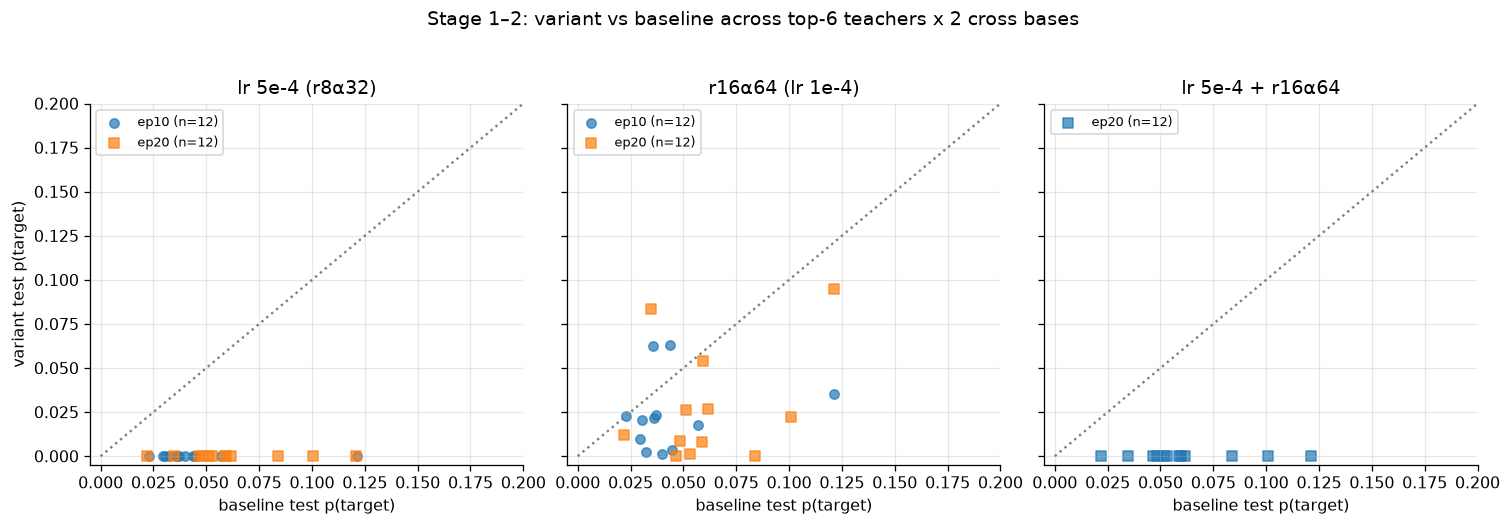

lr 5e-4 (r8α32)        cells= 26  <0.001:  26  >0.005:   0
r16α64 (lr 1e-4)       cells= 24  <0.001:   2  >0.005:  18
lr 5e-4 + r16α64       cells= 12  <0.001:  12  >0.005:   0


In [5]:
VARIANTS = [(5e-4, 8, 32, "lr 5e-4 (r8α32)"), (1e-4, 16, 64, "r16α64 (lr 1e-4)"), (5e-4, 16, 64, "lr 5e-4 + r16α64")]
DOSES2 = [10, 20]
fig, axs = plt.subplots(1, 3, figsize=(13.2, 4.4), sharey=True)
mark = {10: "o", 20: "s"}
for ax, (lr, r, a, lab) in zip(axs, VARIANTS):
    for ep in DOSES2:
        b = cells_df[cells_df.is_baseline_hp & cells_df.ep.eq(ep)].set_index(["teacher_tag", "base"]).mean_test
        v = cells_df[cells_df.lr.eq(lr) & cells_df["rank"].eq(r) & cells_df.alpha.eq(a) & cells_df.ep.eq(ep)] \
            .set_index(["teacher_tag", "base"]).mean_test
        j = b.index.intersection(v.index)
        if not len(j): continue
        ax.scatter(b.loc[j], v.loc[j], s=34, alpha=.7, marker=mark[ep], label=f"ep{ep} (n={len(j)})")
    ax.plot([0, .2], [0, .2], color=".5", ls=":")
    ax.set(title=lab, xlabel="baseline test p(target)", xlim=(-.005, .2), ylim=(-.005, .2))
    ax.legend(fontsize=8)
axs[0].set_ylabel("variant test p(target)")
fig.suptitle("Stage 1–2: variant vs baseline across top-6 teachers x 2 cross bases", y=1.03)
plt.tight_layout(); plt.show()
for lr, r, a, lab in VARIANTS:
    sub = cells_df[cells_df.lr.eq(lr) & cells_df["rank"].eq(r) & cells_df.alpha.eq(a)]
    print(f"{lab:22} cells={len(sub):3d}  <0.001: {int((sub.mean_test < 0.001).sum()):3d}  >0.005: {int((sub.mean_test > 0.005).sum()):3d}")

## 3. The learning-rate cliff (focus cell)

Transfer vs student lr at each dose, log-x, per-seed points overlaid, **at the fixed r8α32 LoRA**. Along this ladder the cliff sits between 1e-4 and 2e-4: at α32, lr 2e-4 is already ≈0 (< 0.005) at every dose (three seeds at ep20 confirm the collapse is not noise), and nothing recovers at shorter doses. **But this is an lr × α effect, not an lr effect** — §8 breaks the confound and shows lr 2e-4 with *small* α (r8α16) is in fact the single strongest cell in the exploration. Read this ladder as "lr at α32," and see §8 for the true control variable. The 5e-5 probe (frontier sweep) shows whether *gentler*-than-standard helps at matched epochs.

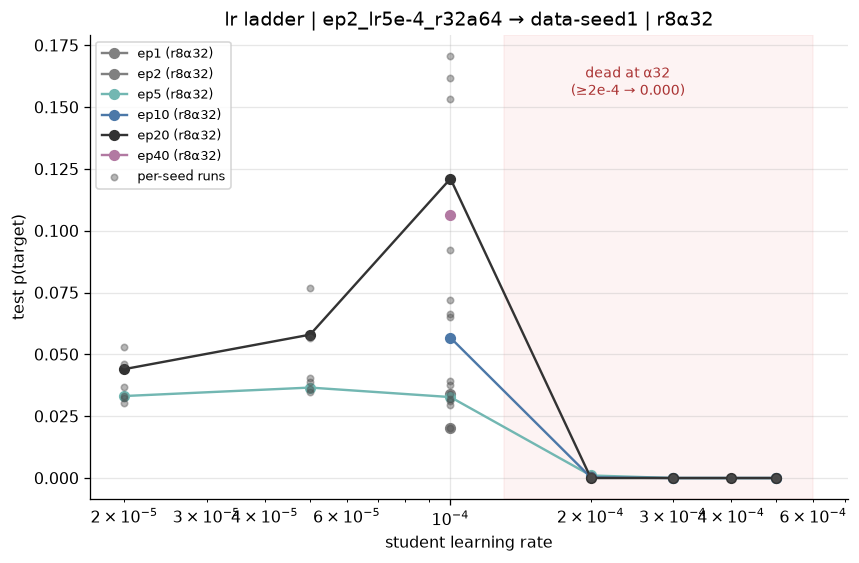

r8α32 cells at lr>=2e-4: 10, all <0.005: True, <0.001: 9 (incl. 18 seed-runs)
  -> but see §8: the dead zone is lr*α >~ 1e-2, not lr >= 2e-4.


In [6]:
lad = focus[focus["rank"].eq(8) & focus.alpha.eq(32) | focus.lr.ge(2e-4) | focus.lr.le(5e-5)]
fig, ax = plt.subplots(figsize=(7.6, 5))
col = {5: "#72b7b2", 10: "#4c78a8", 20: "#333333", 40: "#b279a2"}
for ep in sorted(lad.ep.unique()):
    g = lad[lad.ep.eq(ep) & lad["rank"].eq(8) & lad.alpha.eq(32)].sort_values("lr")
    if not len(g): continue
    ax.plot(g.lr, g.mean_test, marker="o", color=col.get(ep, "gray"), label=f"ep{ep} (r8α32)")
fr = focus_runs[focus_runs["rank"].eq(8) & focus_runs.alpha.eq(32)]
ax.scatter(fr.lr, fr.test, s=16, alpha=.4, color=".3", zorder=3, label="per-seed runs")
ax.axvspan(1.3e-4, 6e-4, color="#e45756", alpha=.07)
ax.text(2.4e-4, .155, "dead at α32\n(≥2e-4 → 0.000)", color="#a33", fontsize=9, ha="center")
ax.set(xscale="log", xlabel="student learning rate", ylabel="test p(target)",
       title=f"lr ladder | {FOCUS_TEACHER} → {BASE_LABEL[FOCUS_BASE]} | r8α32")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()
# NB: this ladder fixes α=32; at α=32, lr>=2e-4 is genuinely dead. But that is an lr*α effect,
# not an lr effect — §8 shows lr 2e-4 with small α (r8α16) is the STRONGEST cell. Scope the
# "all dead" check to α32 so it stays a true statement.
dead = focus[focus.lr.ge(2e-4) & focus["rank"].eq(8) & focus.alpha.eq(32)]
print(f"r8α32 cells at lr>=2e-4: {len(dead)}, all <0.005: {bool((dead.mean_test < 0.005).all())}, "
      f"<0.001: {int((dead.mean_test < 0.001).sum())} (incl. {int(dead.n_seeds.sum())} seed-runs)")
print("  -> but see §8: the dead zone is lr*α >~ 1e-2, not lr >= 2e-4.")

## 4. LoRA scale vs capacity (focus cell, lr 1e-4)

Each point is one (rank, α) cell at lr 1e-4, x = effective scale α/r, size = rank, one panel per dose. Scale is the second aggression knob and behaves like lr: scale 8 (r8α64) dies by ep20 exactly like 2× lr does. Within the surviving region (scale ≤ 4), **capacity helps at gentle scale** — r16α32 (scale 2) posted the best single-seed cell at ep20 (0.168, but mean 0.099 over 3 seeds — within noise of baseline) — while the same capacity at scale 4 (r16α64) sits below baseline. Frontier cells (r16α16, r32α32, r32α64, r64α64, r8α16) slot into these panels as their sweeps land.

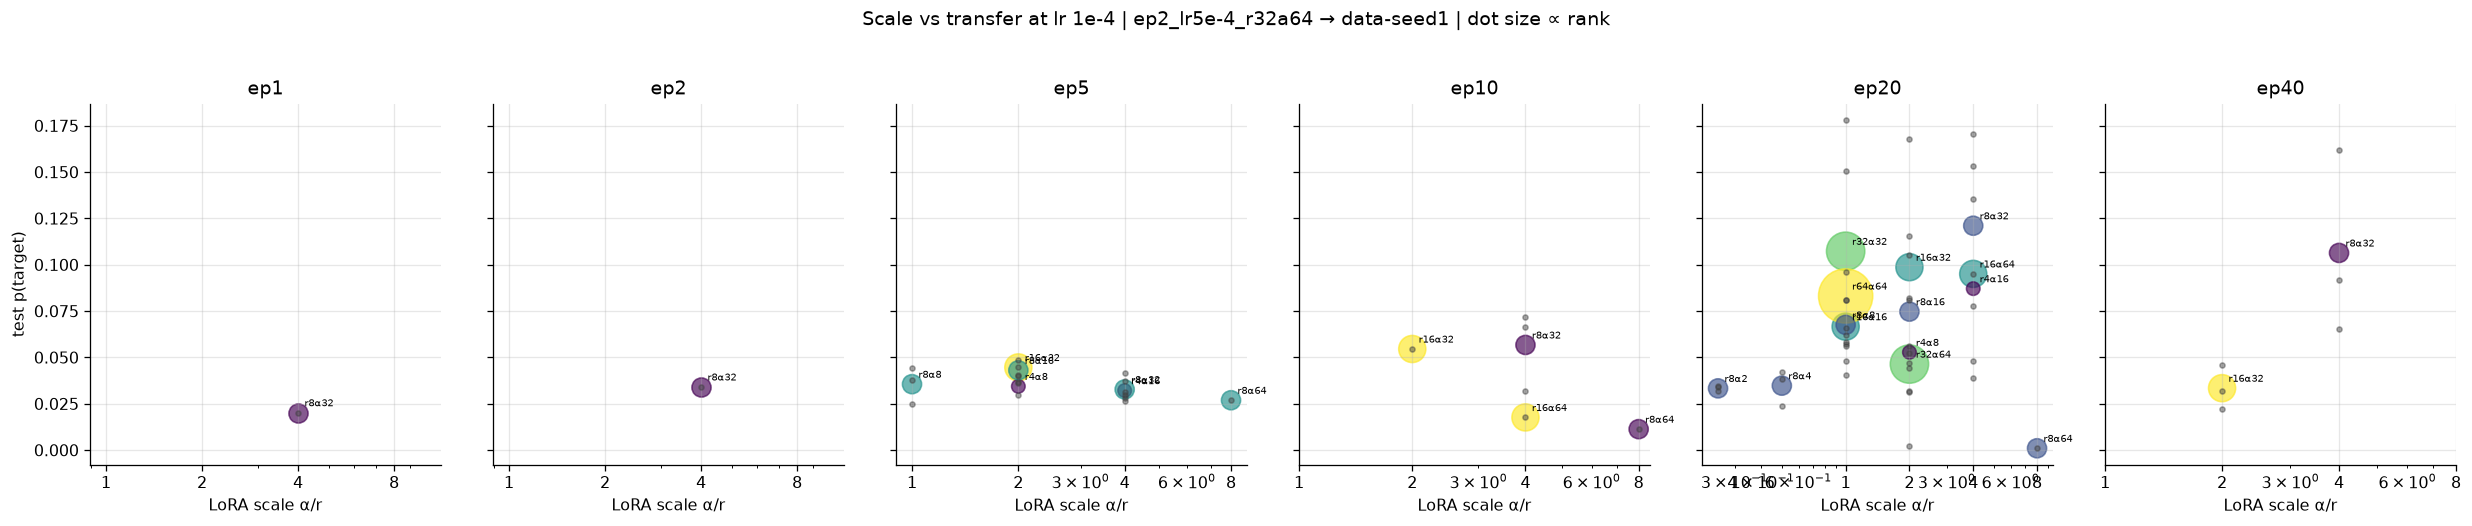

In [7]:
g1 = focus[focus.lr.eq(1e-4)]
eps = sorted(g1.ep.unique())
fig, axs = plt.subplots(1, len(eps), figsize=(3.6 * len(eps), 4.4), sharey=True, squeeze=False)
for ax, ep in zip(axs[0], eps):
    sub = g1[g1.ep.eq(ep)]
    sc = ax.scatter(sub.scale, sub.mean_test, s=18 * sub["rank"], alpha=.65,
                    c=np.log2(sub["rank"]), cmap="viridis")
    rr = focus_runs[focus_runs.lr.eq(1e-4) & focus_runs.ep.eq(ep)]
    ax.scatter(rr.scale, rr.test, s=10, color=".25", alpha=.45, zorder=3)
    for _, row in sub.iterrows():
        ax.annotate(f"r{row['rank']}α{row.alpha}", (row.scale, row.mean_test),
                    textcoords="offset points", xytext=(4, 4), fontsize=6.5)
    ax.set(xscale="log", title=f"ep{ep}", xlabel="LoRA scale α/r", xticks=[1, 2, 4, 8],
           xticklabels=["1", "2", "4", "8"])
axs[0][0].set_ylabel("test p(target)")
fig.suptitle(f"Scale vs transfer at lr 1e-4 | {FOCUS_TEACHER} → {BASE_LABEL[FOCUS_BASE]} | dot size ∝ rank", y=1.03)
plt.tight_layout(); plt.show()

## 5. Dose response of the surviving recipes

Held-out transfer vs student epochs for every lr-1e-4 (rank, α) recipe with any signal, per-seed points overlaid. The baseline ladder (ep1–ep20 from the main sweeps) plus the exploration's ep5/10/20 grid and the ep40 rung. Dose is the one axis that has consistently paid — the question ep40 answers is whether the dose curves are still rising or saturating.

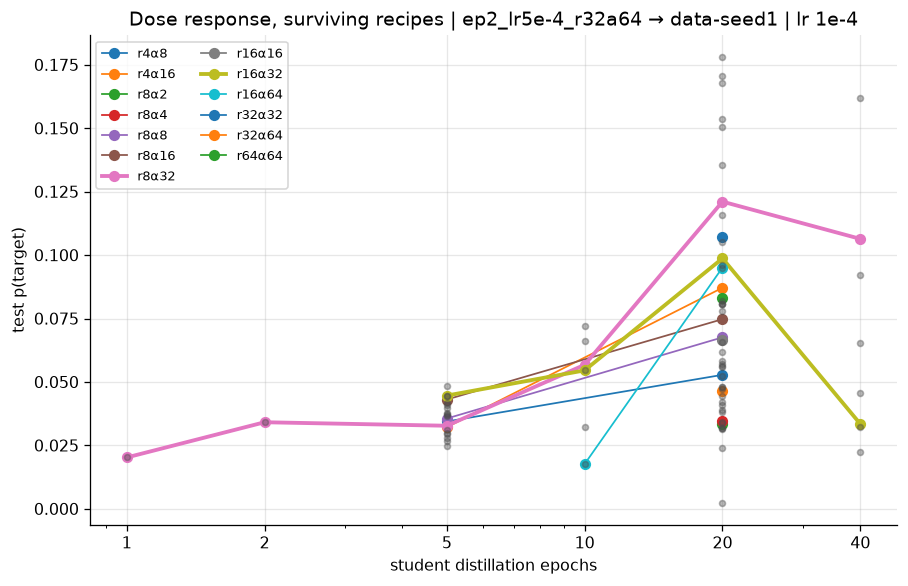

In [8]:
g = focus[focus.lr.eq(1e-4) & focus.scale.le(4)]
fig, ax = plt.subplots(figsize=(8, 5.2))
for (r, a), sub in g.groupby(["rank", "alpha"]):
    sub = sub.sort_values("ep")
    if sub.mean_test.max() < .005 and len(sub) < 2: continue
    lw = 2.4 if (r, a) in [(8, 32), (16, 32)] else 1.1
    ax.plot(sub.ep, sub.mean_test, marker="o", lw=lw, label=f"r{r}α{a}")
rr = focus_runs[focus_runs.lr.eq(1e-4) & focus_runs.scale.le(4)]
ax.scatter(rr.ep, rr.test, s=14, color=".3", alpha=.4, zorder=3)
ax.set(xlabel="student distillation epochs", ylabel="test p(target)", xscale="log",
       xticks=[1, 2, 5, 10, 20, 40], xticklabels=[1, 2, 5, 10, 20, 40],
       title=f"Dose response, surviving recipes | {FOCUS_TEACHER} → {BASE_LABEL[FOCUS_BASE]} | lr 1e-4")
ax.legend(fontsize=8, ncol=2); plt.tight_layout(); plt.show()

## 6. Seed noise vs signal

Every replicated **ep20** cell in one view (ep20 is the dose every conclusion rests on; the ep5/ep10 replicates are excluded so the noise estimate matches the cells being compared). **Left:** within-cell seed SD against the cell mean, one dot per replicated cell, encoded by HP family — **colour = student lr** (the same viridis lr mapping used throughout), **marker = LoRA rank**, **faded = collapsed cells** (mean ≤ 0.005). Noise grows with signal, collapsed cells replicate at ≈0 with ≈0 SD (the cliff is signal, not noise), and the pooled SD over live cells sets the resolution rule used throughout: single-seed contrasts under ~2× pooled SD are not interpretable. **Right:** only the top replicated ep20 cells, as per-seed strips, dots coloured by the same lr mapping — the whole top of the leaderboard overlaps within seed noise, which is why winner claims lean on *reliability* (all seeds off zero) rather than the mean alone.


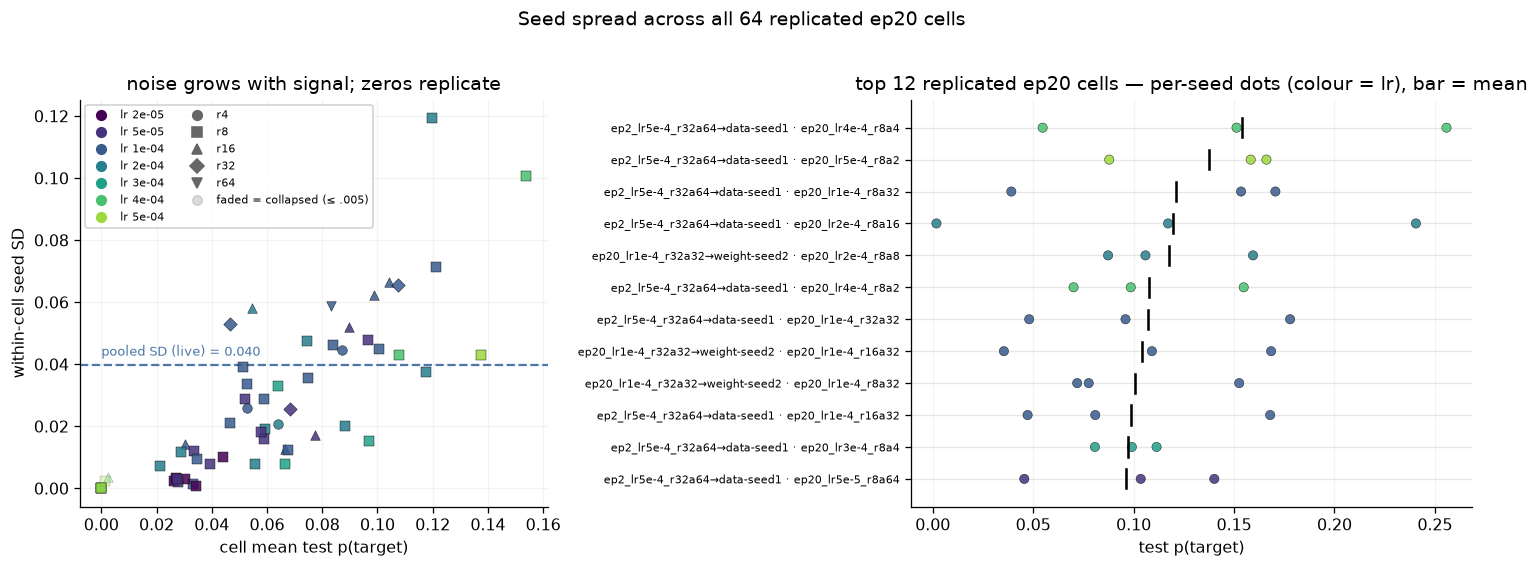

pooled within-cell seed SD over live ep20 cells (mean > 0.005): 0.040 -> single-seed contrasts under ~±0.08 are noise


In [9]:
# Seed noise vs signal at ep20 (the dose every conclusion rests on), two cuts. Left: within-cell
# seed SD vs cell mean for every replicated ep20 cell — colour = student lr, marker = LoRA rank,
# faded = collapsed (mean <= 0.005). Right: per-seed strips for the top replicated ep20 cells,
# dots coloured by the same lr mapping.
from matplotlib.lines import Line2D

rep = cells_df[(cells_df.n_seeds > 1) & cells_df.ep.eq(20)].copy()
if len(rep):
    rep_runs = runs.merge(rep[["teacher_tag", "base", "student_tag"]].drop_duplicates())
    st = rep_runs.groupby(["teacher_tag", "base", "student_tag", "lr", "rank", "alpha"]) \
                 .test.agg(["mean", "std", "count"]).reset_index()
    nz = st[st["mean"] > .005]
    pooled = float(np.sqrt((nz["std"] ** 2).mean()))

    lrs6 = sorted(st.lr.unique())
    lrcol6 = {lr: c for lr, c in zip(lrs6, plt.cm.viridis(np.linspace(0, .85, len(lrs6))))}
    ranks6 = sorted(st["rank"].unique())
    rankmark6 = {r: m for r, m in zip(ranks6, ["o", "s", "^", "D", "v", "P", "X", "*"])}

    NTOP = 12
    fig, (axl, axr) = plt.subplots(1, 2, figsize=(13, 4.8), width_ratios=[1, 1.2])
    for t in st.itertuples():
        dead = t.mean <= .005
        axl.scatter(t.mean, t.std, s=36, color=lrcol6[t.lr], marker=rankmark6[t.rank],
                    alpha=.3 if dead else .85, edgecolor="k", lw=.3, zorder=3)
    axl.axhline(pooled, color="#4c78a8", lw=1.4, ls="--")
    axl.text(0.0, pooled + .002, f"pooled SD (live) = {pooled:.3f}",
             color="#4c78a8", fontsize=8, ha="left", va="bottom")
    handles = ([Line2D([], [], ls="", marker="o", color=lrcol6[lr], label=f"lr {lr:.0e}") for lr in lrs6]
               + [Line2D([], [], ls="", marker=rankmark6[r], color=".4", label=f"r{r}") for r in ranks6]
               + [Line2D([], [], ls="", marker="o", color=".55", alpha=.3,
                         label="faded = collapsed (≤ .005)")])
    axl.legend(handles=handles, fontsize=6.8, ncols=2, loc="upper left", framealpha=.9)
    axl.set(xlabel="cell mean test p(target)", ylabel="within-cell seed SD",
            title="noise grows with signal; zeros replicate")
    axl.grid(alpha=.15)

    top = rep.sort_values("mean_test", ascending=False).head(NTOP).iloc[::-1]
    for i, t in enumerate(top.itertuples()):
        rr = rep_runs[rep_runs.teacher_tag.eq(t.teacher_tag) & rep_runs.base.eq(t.base)
                      & rep_runs.student_tag.eq(t.student_tag)]
        axr.scatter(rr.test, [i] * len(rr), s=34, color=[lrcol6[v] for v in rr.lr],
                    alpha=.85, edgecolor="k", lw=.3, zorder=3)
        axr.plot([t.mean_test] * 2, [i - .3, i + .3], color="black", lw=1.6, zorder=4)
    axr.set_yticks(range(len(top)))
    axr.set_yticklabels([f"{t.teacher_tag}→{BASE_LABEL.get(t.base, t.base)} · {t.student_tag}"
                         for t in top.itertuples()], fontsize=7)
    axr.set(xlabel="test p(target)",
            title=f"top {NTOP} replicated ep20 cells — per-seed dots (colour = lr), bar = mean")
    axr.grid(axis="x", alpha=.15)
    fig.suptitle(f"Seed spread across all {len(st)} replicated ep20 cells", y=1.02)
    plt.tight_layout(); plt.show()
    print(f"pooled within-cell seed SD over live ep20 cells (mean > 0.005): {pooled:.3f} "
          f"-> single-seed contrasts under ~±{2 * pooled:.2f} are noise")
else:
    print("no seed-replicated ep20 cells on disk yet")


## 7. The whole exploration, lineage by lineage

One figure per teacher lineage (teacher config → student base), displayed one after another — the focus lineage first, then the remaining TOP6 × {data-seed1, weight-seed2} lineages. Each figure is the standard HP-sweep layout used throughout these notebooks (`analysis.plots.facet_grid_heatmaps`, the same design as §8's focus grids): within each panel rows = distillation epochs and columns = LoRA rank/α, with one panel per student lr across the row (left→right = increasing lr). **Every HP coordinate the lineage was run on is shown**, and panel width scales with each lineage's own LoRA-column count so cell labels stay readable. Cell value = mean test p(target) over ft seeds; the `n{K}` suffix states how many seeds that mean averages (`n1` = single run, no uncertainty). Red box = the standard recipe (r8α32, lr 1e-4) at ep20. Colour scale capped at 0.2 — cross-init transfer tops out ~0.17, so a 0–1 scale would render everything dark.

Reading the focus figure left→right as increasing lr: lr 5e-4 is dead everywhere while lr 2e-4 is alive at low α — the §8 lr×α correction as territory. Across the other lineages the std-recipe cell sits at-or-near each lineage's best, previewing §10's conclusion that no student recipe beats it beyond noise.


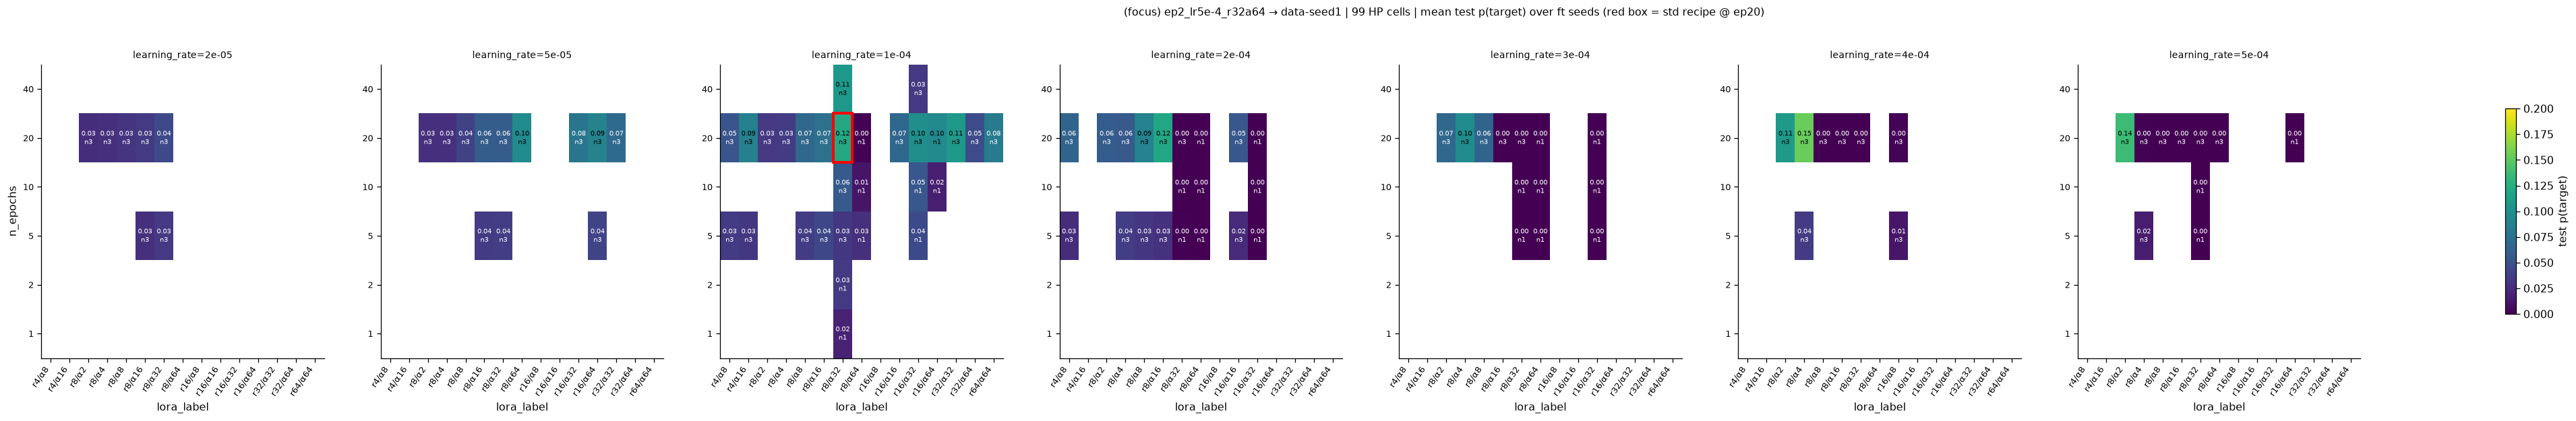

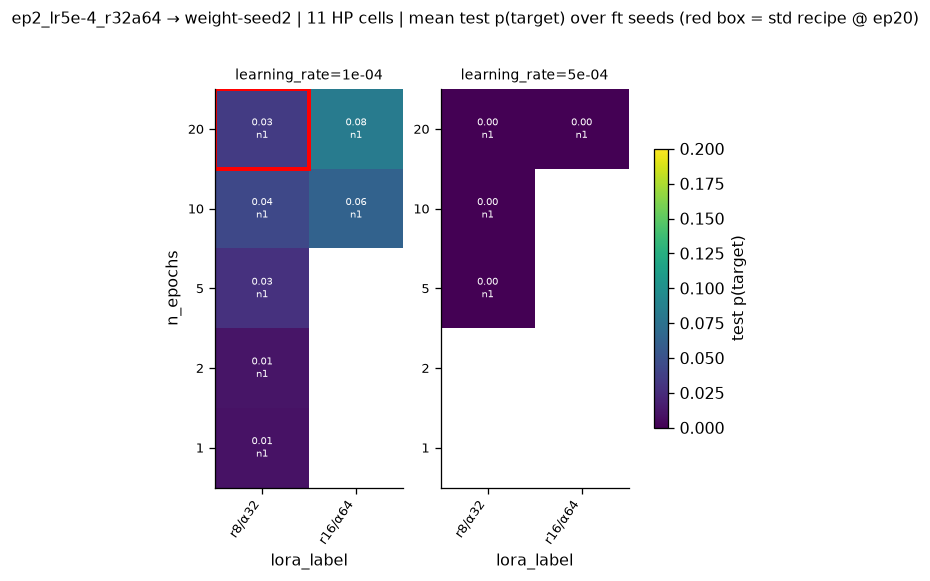

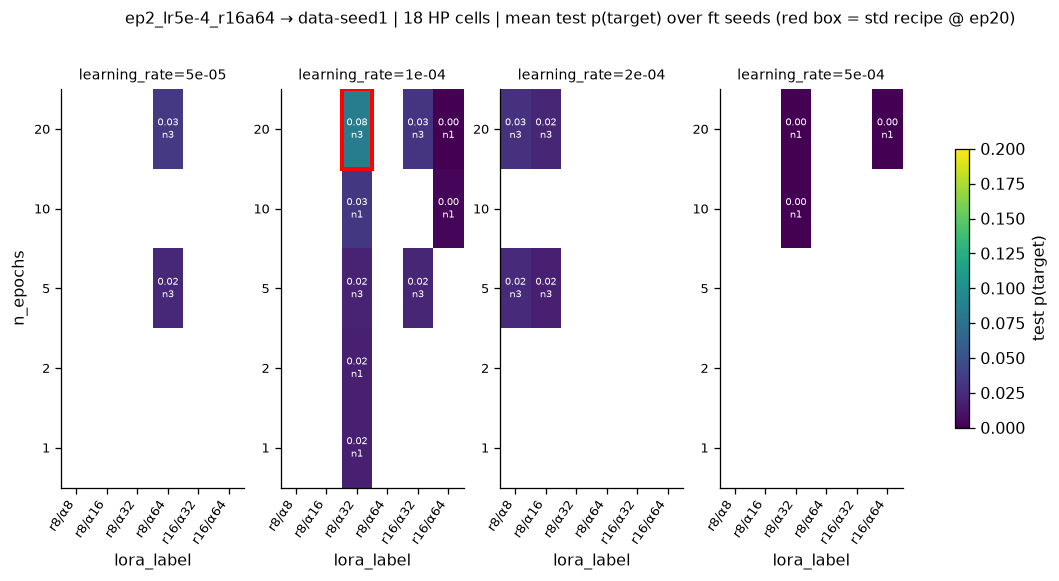

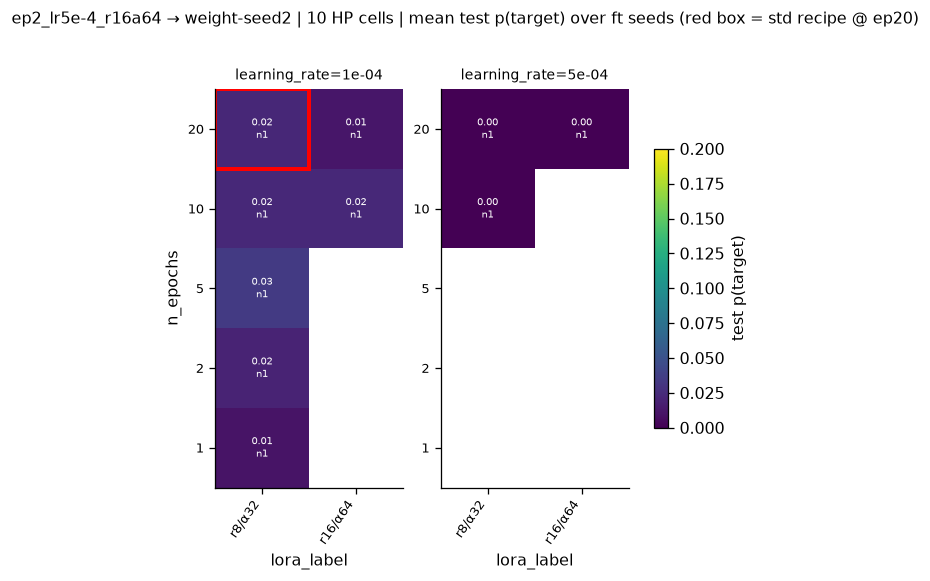

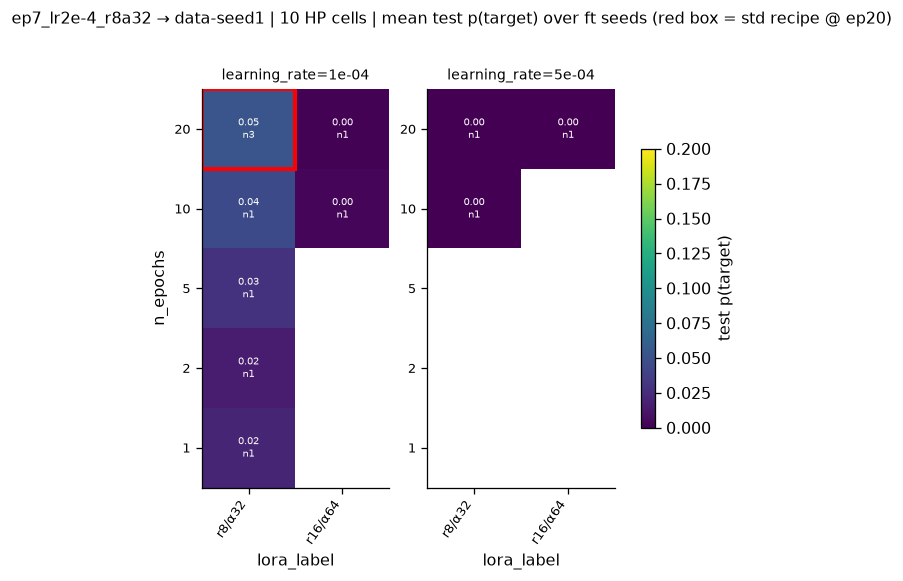

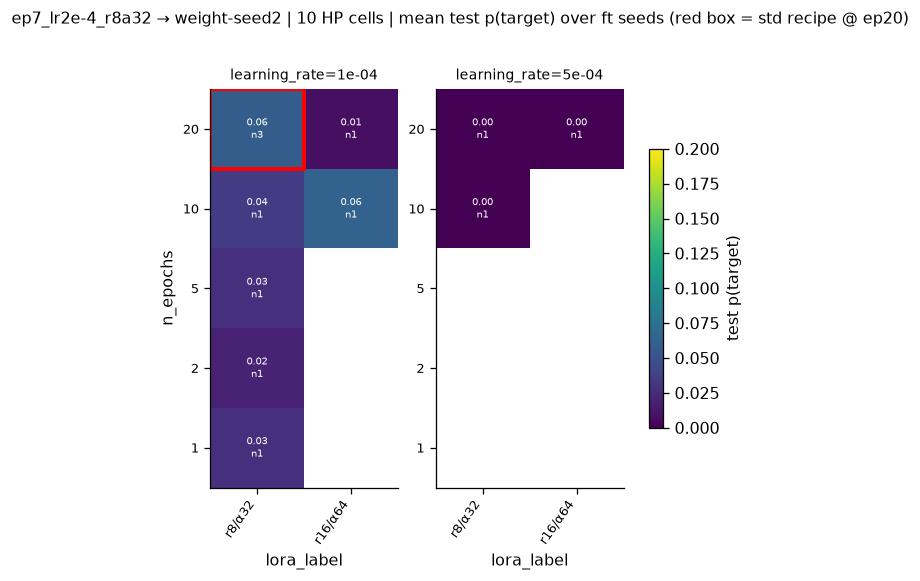

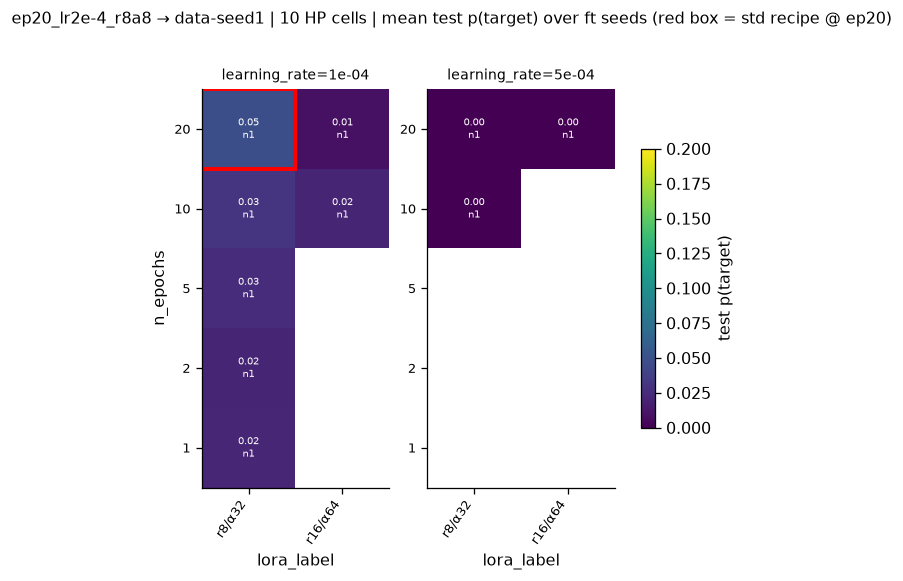

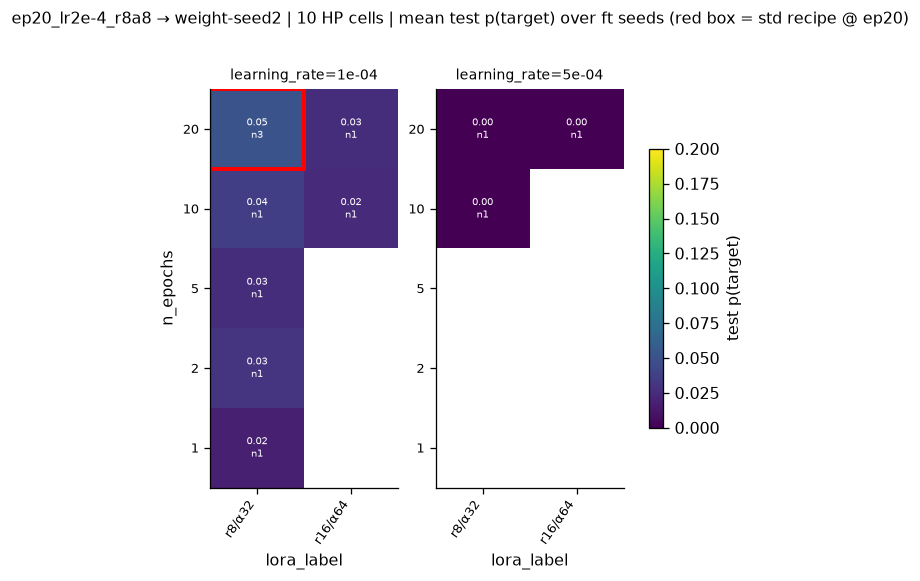

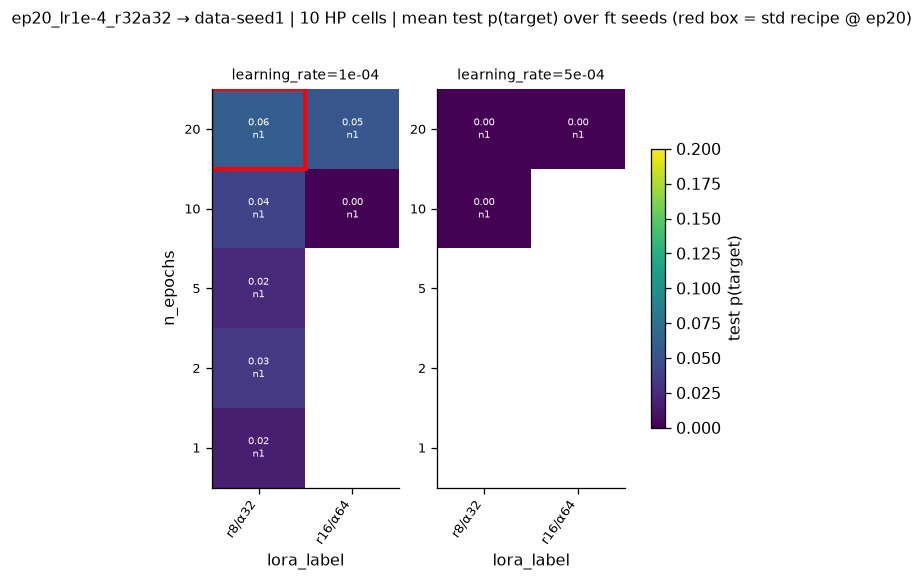

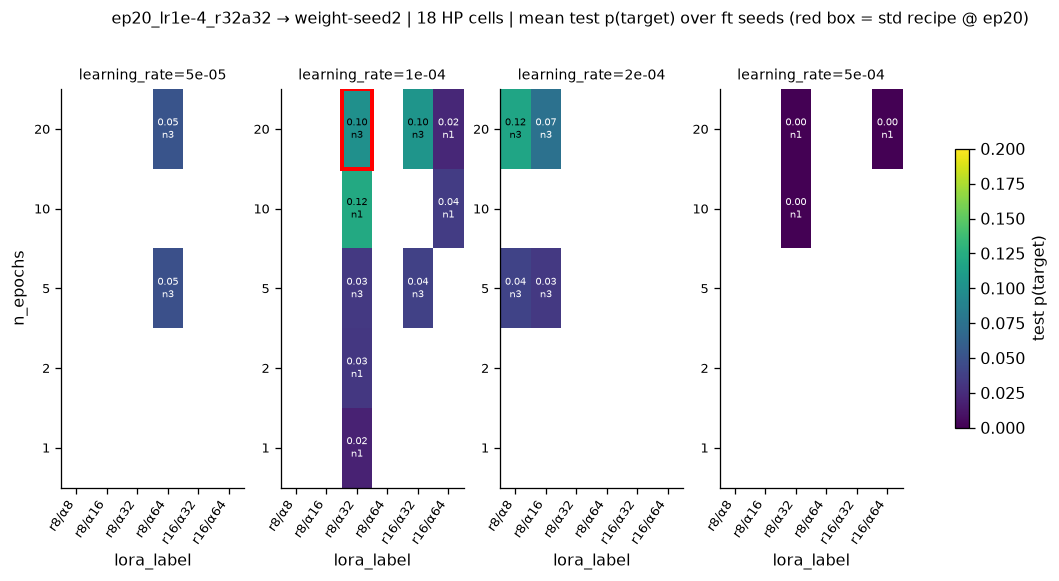

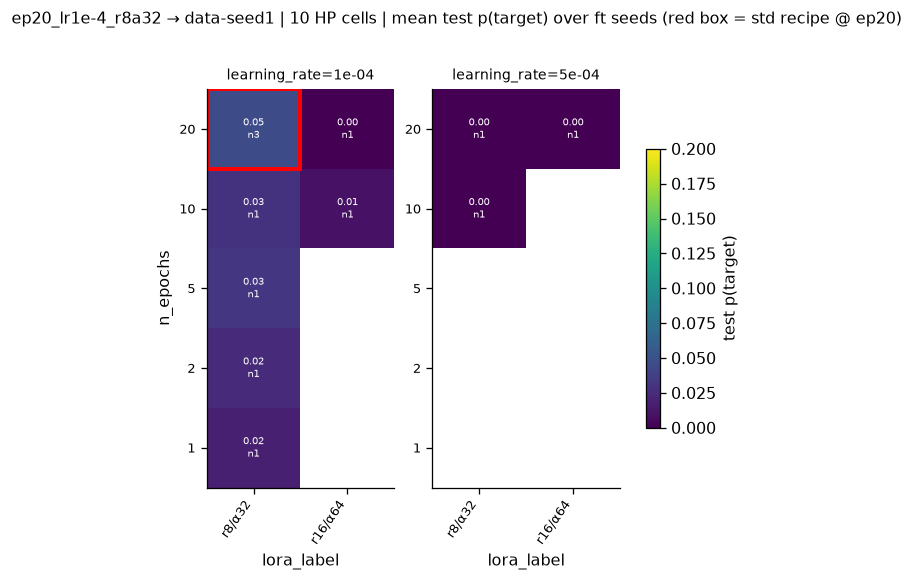

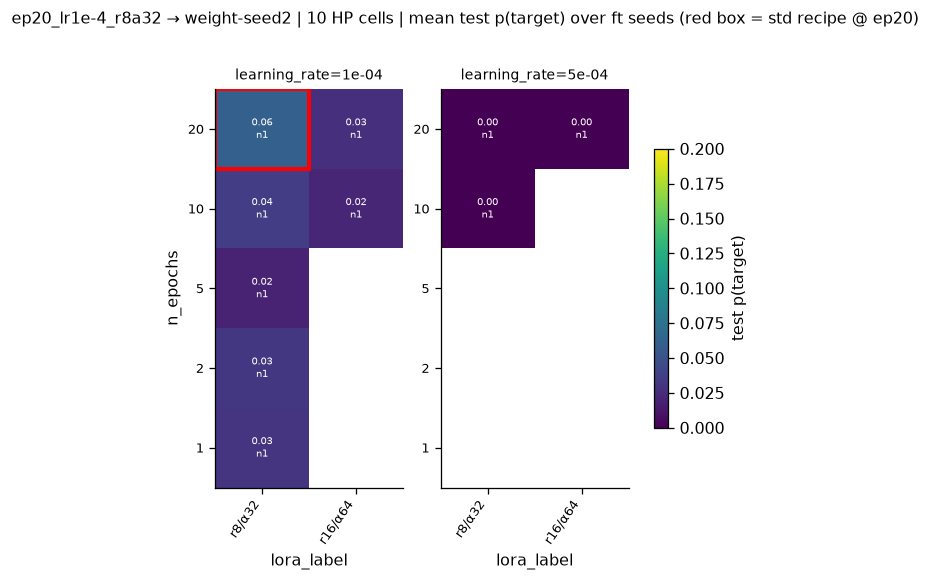

12 lineages, one figure each; all HP coordinates shown (nothing dropped)


In [10]:
from subliminal_learning.analysis import frames, plots as aplots

# One figure per teacher lineage (focus first), displayed one after another — NEVER combined
# into one chart. Each figure is the standard HP-sweep layout used throughout the notebooks:
# y = distillation epochs, x = LoRA rank/α, one panel per student lr across the row.
# Every HP coordinate the lineage was run on is shown; panel width scales with the lineage's
# LoRA-column count so cell labels stay readable.
hp = frames.add_lora_label(runs.rename(
    columns={"ep": "n_epochs", "lr": "learning_rate", "rank": "lora_r", "alpha": "lora_alpha"}))
hp["lineage"] = hp.teacher_tag + " → " + hp.base.map(BASE_LABEL)
focus_name = f"{FOCUS_TEACHER} → {BASE_LABEL[FOCUS_BASE]}"
lineage_order = [focus_name] + [ln for t in TOP6 for b in BASES
                                if (ln := f"{t} → {BASE_LABEL[b]}") != focus_name and ln in set(hp.lineage)]
std_lora = f"r{BASELINE_LORA[0]}/α{BASELINE_LORA[1]}"
for ln in lineage_order:
    sub = hp[hp.lineage.eq(ln)]
    n_cells = sub.groupby(["n_epochs", "learning_rate", "lora_label"], observed=True).ngroups
    tag = "(focus) " if ln == focus_name else ""
    _ = aplots.facet_grid_heatmaps(
        sub, row="n_epochs", col="lora_label", val="test", col_facet="learning_rate",
        show_n=True, vmin=0.0, vmax=0.2,
        panel_w=max(2.4, .45 * sub.lora_label.nunique()),
        highlight=[{"n_epochs": 20, "lora_label": std_lora, "learning_rate": BASELINE_LR}],
        title=f"{tag}{ln} | {n_cells} HP cells | mean test p(target) over ft seeds "
              "(red box = std recipe @ ep20)",
        cbar_label="test p(target)")
plt.show()
print(f"{len(lineage_order)} lineages, one figure each; all HP coordinates shown (nothing dropped)")


## 8. lr 2e-4 is *not* a dead zone — the cliff is lr × α (new 3-seed batch, 2026-07-23/24)

Stages 1–7 concluded the student-lr cliff sits between 1e-4 and 2e-4 "and is absolute." That was **confounded by LoRA scale**: every lr-2e-4 cell run up to then also carried α ≥ 32. This batch breaks the confound — lr 2e-4 at **small α** (r8α8, r8α16, r16α16) × {ep5, ep20} × 3 seeds, plus an r8α64 lr-rescue (lr 5e-4 vs 5e-5) — and overturns the headline:

- **lr 2e-4 transfers fine at low α.** `r8α16` at lr 2e-4 ep20 is the **single strongest cell in the whole exploration** (0.120, 3-seed), with `r8α8` (0.088) and `r16α16` (0.055) also clearly alive — against < 0.001 for the α ≥ 32 cells at the *same* lr. So lr alone is not the toxin.
- **The governing scalar is the product lr × α** (the raw LoRA-B update magnitude), not lr or α/r alone: every ep20 cell survives at lr×α ≤ 3.2e-3 and is dead by lr×α ≥ ~1e-2, with a *mixed* boundary near 6.4e-3 where a lower lr or larger rank still rescues. The clean discriminator is lr×α, not lr×(α/r): `r8α16` and `r16α32` share the same α/r=2 at lr 2e-4, but only the lower-α one (r8α16, lr×α=3.2e-3) lives — the higher-α one (r16α32, lr×α=6.4e-3) collapses. This unifies the notebook's two "aggression knobs" into one.
- **The r8α64 lr-rescue is the within-architecture proof.** Identical adapter, only the lr changes: 0.000 at lr 5e-4 → **0.096 at lr 5e-5** (lr×α 3.2e-2 → 3.2e-3) — the config Angela intended, and one of the most *reliable* cells (seeds 0.046–0.140, no near-zero seed).
- **Dose still pays:** ep20 ≫ ep5 for all three low-α lr-2e-4 recipes (≈3–4× at matched HP), consistent with §5.

Caveat unchanged from §6: seed spread is large — r8α16's headline 0.120 rests on 0.240/0.117/**0.002**. The *reliable* winners are `r8α64 @ lr5e-5` (0.096) and `r8α8 @ lr2e-4` (0.088), both with all three seeds off zero. This refines — and partly reverses — the "dead zone" language in §3, §7, and the checklist below: the dead zone is `lr × α ≳ 1e-2`, not `lr ≥ 2e-4`.

Charts: first the lr×α money plot (colour = student lr, marker = LoRA rank — every colour and shape falls on the same curve). Then the house 2D grids at ep20, one figure per teacher config displayed sequentially: the focus lineage's full rank × lr surface per LoRA scale, followed by the same cut for each §10 teacher lineage (menu coordinates only).


student_tag,ep,lr,rank,alpha,lr_alpha,mean_test,n_seeds,seed_min,seed_max
ep20_lr2e-4_r8a16,20,2e-04,8,16,3.2e-03,0.120,3,0.002,0.241
ep20_lr5e-5_r8a64,20,5e-05,8,64,3.2e-03,0.096,3,0.046,0.140
ep20_lr2e-4_r8a8,20,2e-04,8,8,1.6e-03,0.088,3,0.068,0.108
ep20_lr2e-4_r16a16,20,2e-04,16,16,3.2e-03,0.054,3,0.000,0.116
ep5_lr2e-4_r8a8,5,2e-04,8,8,1.6e-03,0.032,3,0.026,0.043
ep5_lr2e-4_r8a16,5,2e-04,8,16,3.2e-03,0.029,3,0.021,0.040
ep5_lr2e-4_r16a16,5,2e-04,16,16,3.2e-03,0.025,3,0.012,0.044
ep20_lr5e-4_r8a64,20,5e-04,8,64,3.2e-02,0.000,3,0.000,0.000


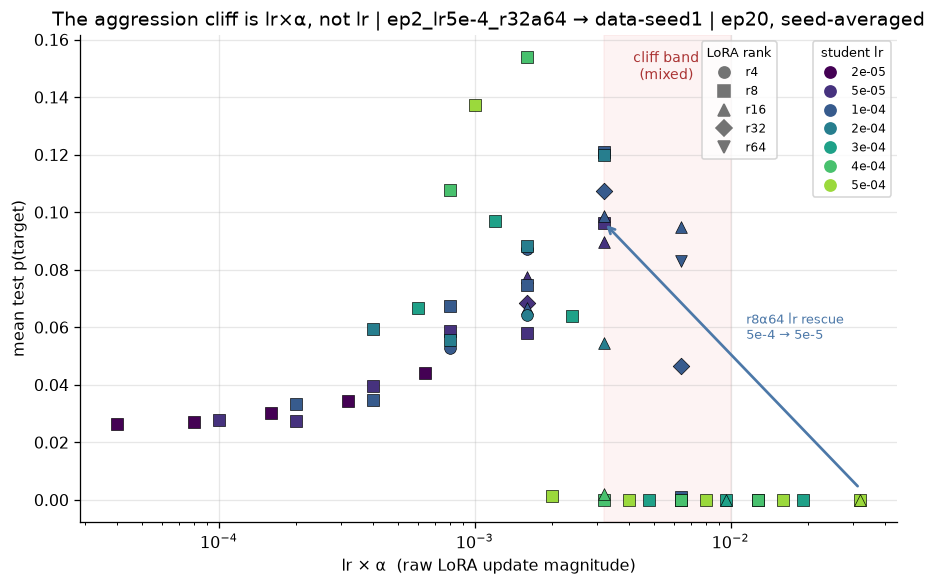

lr 2e-4, ep20 — survives at low alpha, dies at alpha>=32:
  r8a2   (lr*a=4.0e-04)  p=0.059  n3
  r8a4   (lr*a=8.0e-04)  p=0.056  n3
  r4a8   (lr*a=1.6e-03)  p=0.064  n3
  r8a8   (lr*a=1.6e-03)  p=0.088  n3
  r8a16  (lr*a=3.2e-03)  p=0.120  n3
  r16a16  (lr*a=3.2e-03)  p=0.054  n3
  r8a32  (lr*a=6.4e-03)  p=0.000  n3
  r16a32  (lr*a=6.4e-03)  p=0.000  n1
  r8a64  (lr*a=1.3e-02)  p=0.000  n1
r8a64 lr-rescue: lr5e-4=0.000 -> lr5e-5=0.096


In [11]:
# New 3-seed batch (2026-07-23/24): break the lr-2e-4 / alpha confound + the r8a64 lr-rescue.
BATCH = ["ep20_lr2e-4_r8a8", "ep20_lr2e-4_r8a16", "ep20_lr2e-4_r16a16",
         "ep5_lr2e-4_r8a8", "ep5_lr2e-4_r8a16", "ep5_lr2e-4_r16a16",
         "ep20_lr5e-4_r8a64", "ep20_lr5e-5_r8a64"]
batch = focus[focus.student_tag.isin(BATCH)].assign(lr_alpha=lambda d: d.lr * d.alpha) \
             .sort_values("mean_test", ascending=False)
tbl = batch[["student_tag", "ep", "lr", "rank", "alpha", "lr_alpha", "mean_test", "n_seeds", "seed_min", "seed_max"]]
display(tbl.style.format({"lr": "{:.0e}", "lr_alpha": "{:.1e}", "mean_test": "{:.3f}",
                          "seed_min": "{:.3f}", "seed_max": "{:.3f}"})
        .set_caption("New 3-seed batch (focus cell) — sorted by mean test p(target)").hide(axis="index"))

# Money plot: transfer vs lr*alpha across all ep20 focus cells, seed-averaged; colour = lr
# family (the viridis lr mapping used throughout), marker = LoRA rank. Points of every colour
# and shape fall on the same curve — "the cliff is the product, not lr or rank" in one picture.
f20 = focus[focus.ep.eq(20)].assign(lr_alpha=lambda d: d.lr * d.alpha)
lrs20 = sorted(f20.lr.unique())
lrcol20 = {lr: c for lr, c in zip(lrs20, plt.cm.viridis(np.linspace(0, .85, len(lrs20))))}
fig, ax = plt.subplots(figsize=(8, 5.2))
ax.axvspan(3.2e-3, 1e-2, color="#e45756", alpha=.07)
from matplotlib.transforms import blended_transform_factory
ax.text(5.6e-3, .97, "cliff band\n(mixed)", color="#a33", fontsize=8.5, ha="center", va="top",
        transform=blended_transform_factory(ax.transData, ax.transAxes))
ranks20 = sorted(f20["rank"].unique())
rankmark20 = {r: m for r, m in zip(ranks20, ["o", "s", "^", "D", "v", "P", "X", "*"])}
for (lr, r), g in f20.groupby(["lr", "rank"]):
    ax.scatter(g.lr_alpha, g.mean_test, s=54, color=lrcol20[lr], marker=rankmark20[r],
               edgecolor="k", lw=.4, zorder=3)
lo = f20[f20.student_tag.eq("ep20_lr5e-4_r8a64")]
hi = f20[f20.student_tag.eq("ep20_lr5e-5_r8a64")]
if len(lo) and len(hi):
    ax.annotate("", xy=(hi.lr_alpha.iloc[0], hi.mean_test.iloc[0]),
                xytext=(lo.lr_alpha.iloc[0], lo.mean_test.iloc[0] + .004),
                arrowprops=dict(arrowstyle="->", color="#4c78a8", lw=1.7))
    ax.text(1.15e-2, .056, "r8α64 lr rescue\n5e-4 → 5e-5", color="#4c78a8", fontsize=8, ha="left")
ax.set(xscale="log", xlabel="lr × α  (raw LoRA update magnitude)", ylabel="mean test p(target)",
       title=f"The aggression cliff is lr×α, not lr | {FOCUS_TEACHER} → {BASE_LABEL[FOCUS_BASE]} | ep20, seed-averaged")
from matplotlib.lines import Line2D
leg_lr = ax.legend(handles=[Line2D([], [], ls="", marker="o", ms=7, color=lrcol20[lr],
                                   label=f"{lr:.0e}") for lr in lrs20],
                   title="student lr", fontsize=7.5, title_fontsize=8, loc="upper right")
ax.add_artist(leg_lr)
ax.legend(handles=[Line2D([], [], ls="", marker=rankmark20[r], ms=7, color=".45", label=f"r{r}")
                   for r in ranks20],
          title="LoRA rank", fontsize=7.5, title_fontsize=8, loc="upper right",
          bbox_to_anchor=(.86, 1))
plt.tight_layout(); plt.show()

# The headline correction, quantified: lr 2e-4 at ep20, split by alpha.
lr2 = focus[focus.lr.eq(2e-4) & focus.ep.eq(20)].sort_values("alpha")
print("lr 2e-4, ep20 — survives at low alpha, dies at alpha>=32:")
for t in lr2.itertuples():
    print(f"  r{t.rank}a{t.alpha:<3d} (lr*a={t.lr * t.alpha:.1e})  p={t.mean_test:.3f}  n{t.n_seeds}")
resc = {t.student_tag: t.mean_test for t in focus[focus.student_tag.isin(
    ['ep20_lr5e-4_r8a64', 'ep20_lr5e-5_r8a64'])].itertuples()}
print(f"r8a64 lr-rescue: lr5e-4={resc.get('ep20_lr5e-4_r8a64', float('nan')):.3f} "
      f"-> lr5e-5={resc.get('ep20_lr5e-5_r8a64', float('nan')):.3f}")

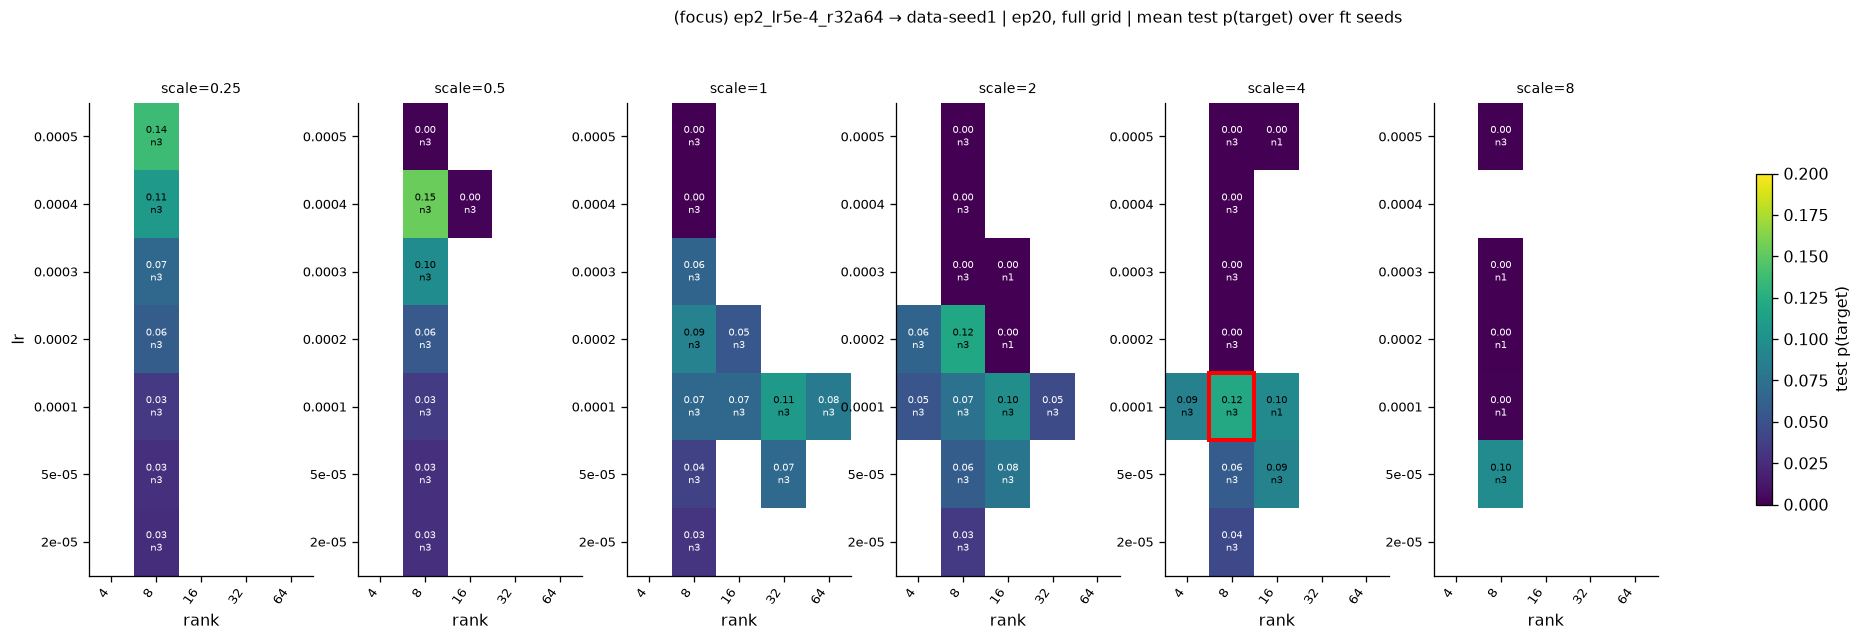

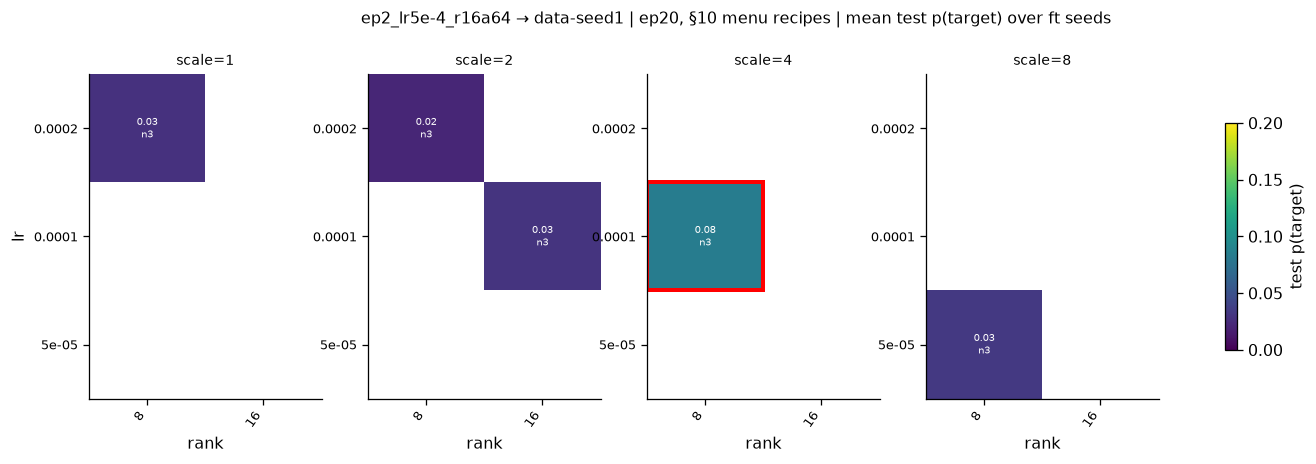

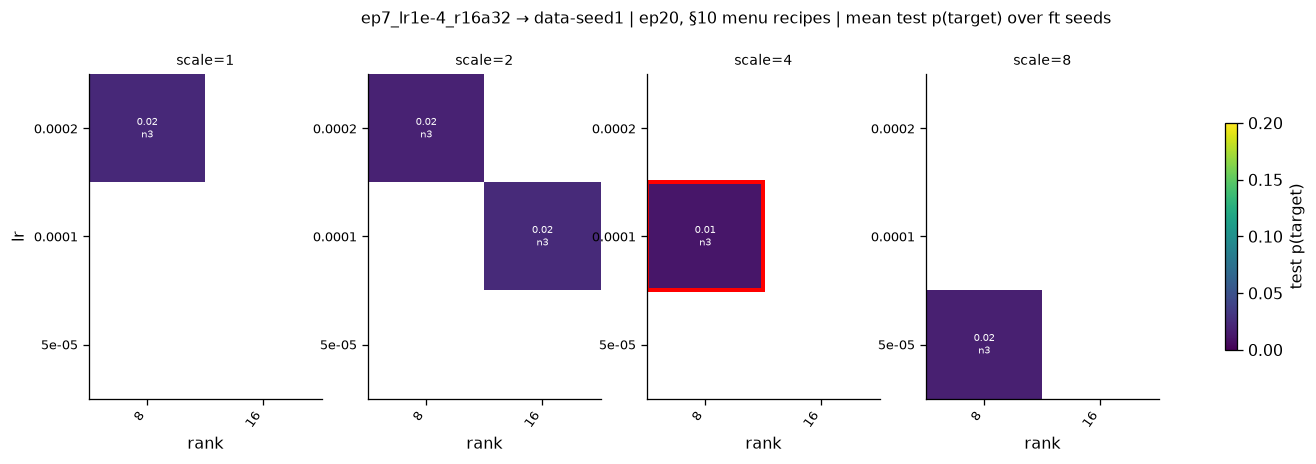

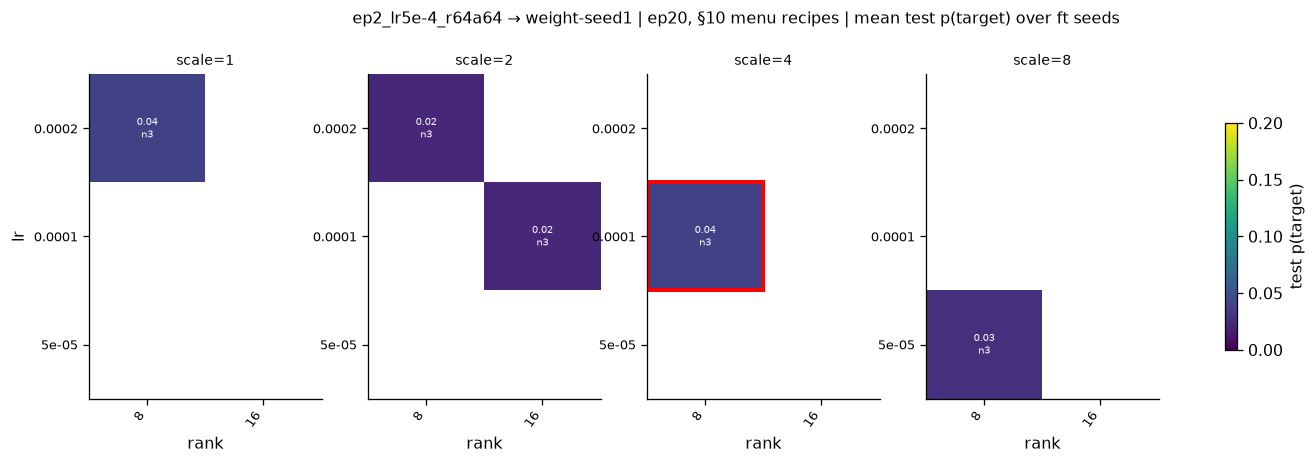

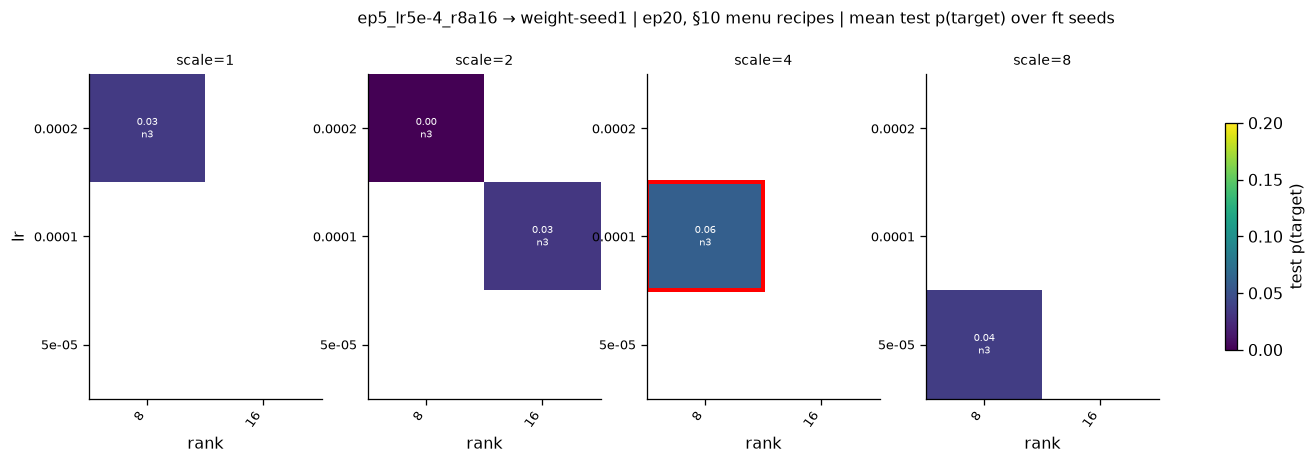

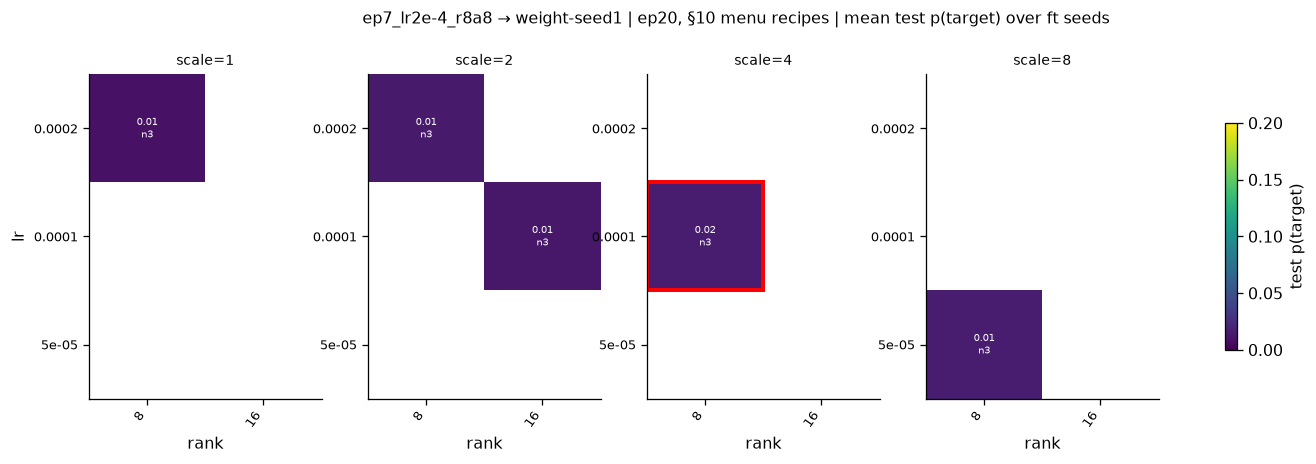

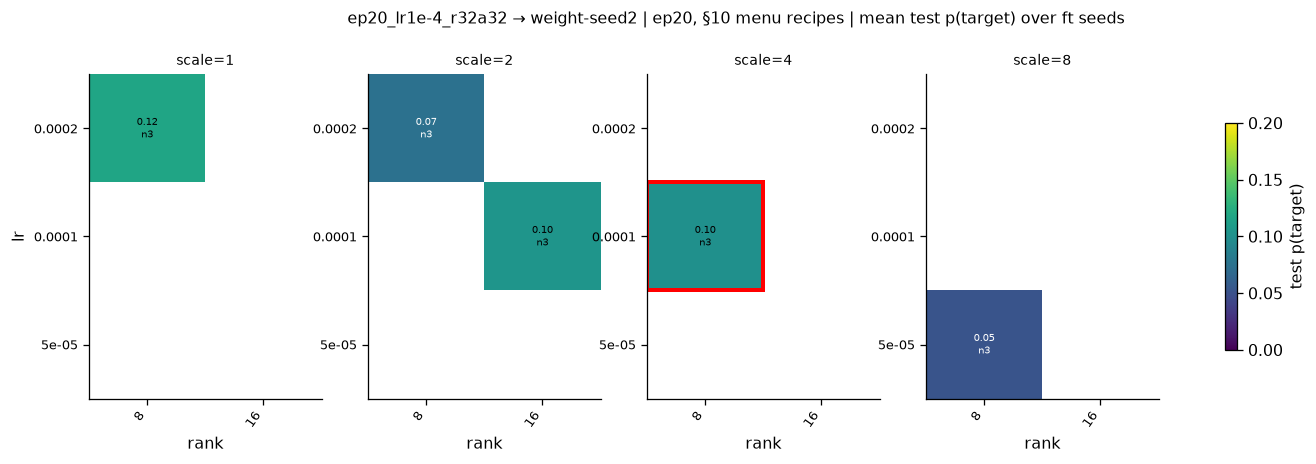

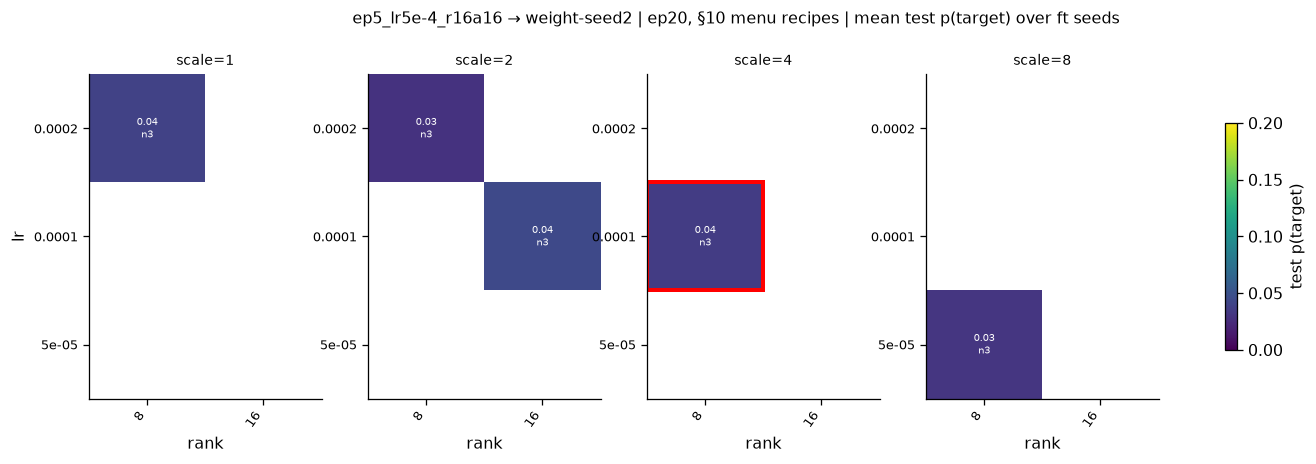

In [12]:
# The same cut in the house 2D-grid style — one figure per teacher config at ep20, displayed
# sequentially: x = LoRA rank, y = student lr, one panel per LoRA scale (α/r). First the focus
# lineage over its FULL dense ep20 grid, then each §10 menu lineage over the five menu recipes
# (std + four gentle; blank = not in the menu). Red box = the std recipe (lr 1e-4, r8, α/r = 4).
from subliminal_learning.analysis import plots as aplots

g20 = focus_runs[focus_runs.ep.eq(20)].copy()
_ = aplots.facet_heatmaps(
    g20, row="lr", col="rank", facet="scale", val="test",
    show_n=True, vmin=0.0, vmax=0.2, highlight=(1e-4, 8, 4.0),
    title=f"(focus) {FOCUS_TEACHER} → {BASE_LABEL[FOCUS_BASE]} | ep20, full grid | "
          "mean test p(target) over ft seeds",
    cbar_label="test p(target)")
m20 = menu_runs[menu_runs.ep.eq(20) & ~menu_runs.is_focus].assign(scale=lambda d: d.alpha / d["rank"])
for ln in LINEAGES[1:]:
    sub = m20[m20.lineage.eq(ln)]
    if not len(sub): continue
    _ = aplots.facet_heatmaps(
        sub, row="lr", col="rank", facet="scale", val="test",
        show_n=True, vmin=0.0, vmax=0.2, highlight=(1e-4, 8, 4.0),
        title=f"{ln} | ep20, §10 menu recipes | mean test p(target) over ft seeds",
        cbar_label="test p(target)")
plt.show()


## 9. The other five teachers — probe only, no HP grid

Everything in §3–§8 is the single focus lineage `ep2_lr5e-4_r32a64 → data-seed1` (53 student cells). The other five top-6 teachers each got only the **stage-1/2 probe** — the standard-recipe dose ladder (r8α32, lr 1e-4, ep {1,2,5,10,20}) plus the three "stronger-student" variants at ep 10/20 — on **both** cross bases (~10 cells each), and nothing else. This cell shows all six on the one cut they share (the standard-recipe dose curve) so the focus choice is legible, and tabulates the ep20 standard-vs-variant contrast per teacher. Two things to read: (1) the focus teacher is among the strongest at the standard recipe, which is why it was picked to carry the grid; (2) the variant collapse (§2) holds for *every* teacher — so the §8 lr×α law is the natural next thing to test on a second teacher. **§10 now does exactly that, on seven of them.**

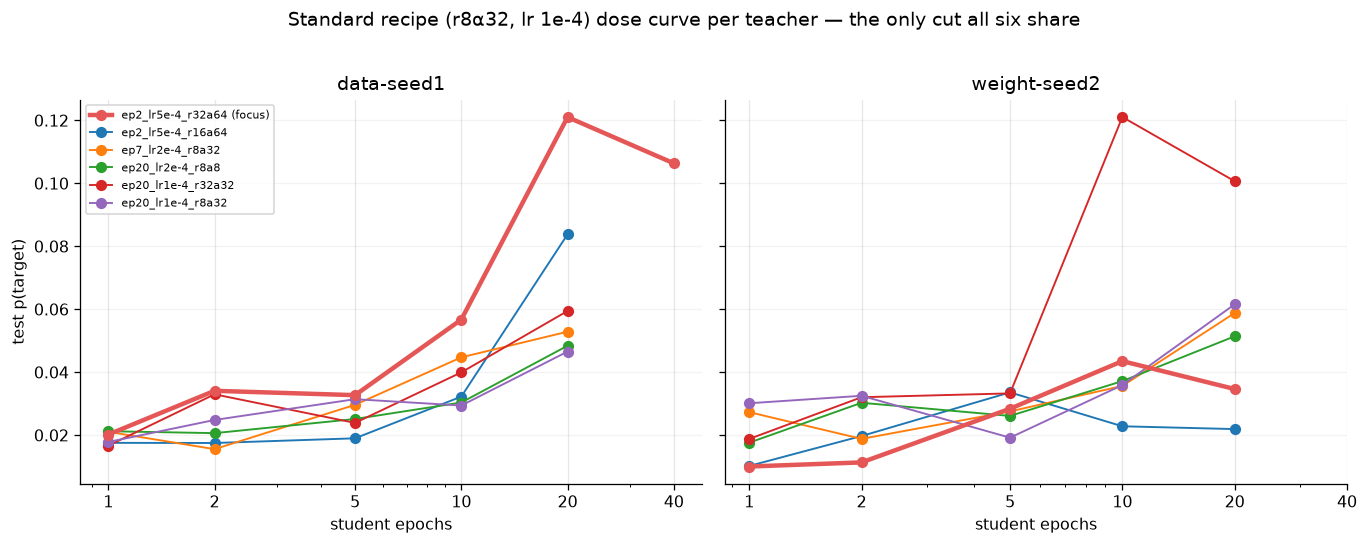

teacher,base,baseline,var_lr5e4,var_r16a64,var_both
ep2_lr5e-4_r32a64,data-seed1,0.121,0.000,0.095,0.000
ep2_lr5e-4_r32a64,weight-seed2,0.035,0.000,0.084,0.000
ep2_lr5e-4_r16a64,data-seed1,0.084,0.000,0.000,0.000
ep2_lr5e-4_r16a64,weight-seed2,0.022,0.000,0.012,0.000
ep7_lr2e-4_r8a32,data-seed1,0.053,0.000,0.001,0.000
ep7_lr2e-4_r8a32,weight-seed2,0.059,0.000,0.008,0.000
ep20_lr2e-4_r8a8,data-seed1,0.048,0.000,0.009,0.000
ep20_lr2e-4_r8a8,weight-seed2,0.051,0.000,0.026,0.000
ep20_lr1e-4_r32a32,data-seed1,0.059,0.000,0.054,0.000
ep20_lr1e-4_r32a32,weight-seed2,0.101,0.000,0.022,0.000


Only ep2_lr5e-4_r32a64 carries the lr/α/rank grid (§3-§8); the rest stop at this probe.


In [13]:
# The five non-focus teachers got only the stage-1/2 probe (standard-recipe dose ladder + 3 variants),
# never the lr/α/rank grid of §3-§8. Show all six on the one cut they share, so the focus pick is legible.
bl = cells_df[cells_df.is_baseline_hp]  # r8α32, lr1e-4 dose ladder — present for every teacher x base
fig, axs = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
for ax, base in zip(axs, BASES):
    for tag in TOP6:
        g = bl[bl.teacher_tag.eq(tag) & bl.base.eq(base)].sort_values("ep")
        if not len(g): continue
        foc = tag == FOCUS_TEACHER
        ax.plot(g.ep, g.mean_test, marker="o", lw=2.8 if foc else 1.2,
                color="#e45756" if foc else None, zorder=5 if foc else 2,
                label=tag + (" (focus)" if foc else ""))
    ax.set(xscale="log", xticks=[1, 2, 5, 10, 20, 40], xticklabels=[1, 2, 5, 10, 20, 40],
           xlabel="student epochs", title=BASE_LABEL[base]); ax.grid(axis="y", alpha=.15)
axs[0].set_ylabel("test p(target)"); axs[0].legend(fontsize=7)
fig.suptitle("Standard recipe (r8α32, lr 1e-4) dose curve per teacher — the only cut all six share", y=1.02)
plt.tight_layout(); plt.show()

# ep20: standard recipe vs the three stage-1/2 variants, per (teacher, base). Variants collapse everywhere.
def m20(tag, base, lr, r, a):
    q = cells_df[cells_df.teacher_tag.eq(tag) & cells_df.base.eq(base) & cells_df.ep.eq(20)
                 & cells_df.lr.eq(lr) & cells_df["rank"].eq(r) & cells_df.alpha.eq(a)]
    return q.mean_test.iloc[0] if len(q) else np.nan
vt = pd.DataFrame([dict(
    teacher=tag, base=BASE_LABEL[base],
    baseline=m20(tag, base, 1e-4, 8, 32), var_lr5e4=m20(tag, base, 5e-4, 8, 32),
    var_r16a64=m20(tag, base, 1e-4, 16, 64), var_both=m20(tag, base, 5e-4, 16, 64),
) for tag in TOP6 for base in BASES])
display(vt.style.format({c: "{:.3f}" for c in ["baseline", "var_lr5e4", "var_r16a64", "var_both"]}, na_rep="–")
        .set_caption("ep20 test p(target): standard recipe vs the 3 stage-1/2 variants, all six teachers")
        .hide(axis="index"))
print("Only", FOCUS_TEACHER, "carries the lr/α/rank grid (§3-§8); the rest stop at this probe.")

## 10. Does the §8 result hold on other teachers? — no; std stays the default (2026-07-24)

§3–§8 mapped the student-HP surface of **one** lineage (the focus, `ep2_lr5e-4_r32a64 → data-seed1`). This section asks a single question: **is the §8 recipe ranking a property of the recipes, or of that one lineage?**

The test: seven more teacher configs — spanning strong and mid-strength std-recipe transfer, on three student bases including `weight-seed1` (new to this notebook) — each ran the identical five-recipe **menu**: the standard recipe (`r8α32 @ lr 1e-4`) plus the four §8 gentle recipes (`r8α8@2e-4`, `r8α16@2e-4`, `r16α32@1e-4`, `r8α64@5e-5` — all at lr×α ≤ 3.2e-3), at {ep5, ep20} × 3 ft seeds. Jobs: `run_logs/hp_t{2..8}_*_jobs.txt`, drained 2026-07-24, all 70 new cells at 3/3 seeds. The per-teacher heatmap grids for these lineages are **at the end of §8**; below: the ep20 table, then one chart putting each lineage's five recipes side by side.

The answer, in three parts:

- **No gentle recipe beats std anywhere.** Best gain over a lineage's own std baseline is **+0.017** — well inside the ±0.06 noise band from §6 — while std wins by 0.050 on the strongest new lineage. §8's star `r8α16@2e-4` never exceeds 0.074 off-focus. §8 mapped the focus cell's local surface, not a transferable ranking.
- **Gentle is still safe — with one real exception.** 69/70 new cells are alive, but `r8α16@2e-4` under `ep5_lr5e-4_r8a16 → weight-seed1` is dead on all three seeds (0.000/0.000/0.001) despite gentle lr×α — the safety half of the lr×α law is necessary, not sufficient.
- **Teacher lineage sets the ceiling.** Std-recipe ep20 spans 0.012–0.101 across the seven new lineages — nearly an order of magnitude — and no recipe choice rescues a weak lineage. Teacher config × base selection moves transfer far more than any student-HP move inside the safe region.


In [14]:
# ep20 results per (teacher lineage, student recipe) — each cell = mean over 3 ft seeds.
p20 = menu_cells[menu_cells.ep.eq(20)].pivot_table(index="lineage", columns="recipe", values="mean_test") \
    .reindex(index=LINEAGES, columns=RECIPE_ORDER)
p20["best gentle − std"] = p20[RECIPE_ORDER[1:]].max(axis=1) - p20[RECIPE_ORDER[0]]
display(p20.style.format("{:.3f}", na_rep="–").format("{:+.3f}", subset=["best gentle − std"])
        .set_caption("ep20 mean test p(target) per (teacher lineage, student recipe); 3 ft seeds per cell. "
                     "Row 1 = the §8 focus lineage. Last column: best gentle recipe minus the same "
                     "lineage's own std — positive beyond ±0.06 would mean a gentle recipe beat std."))


recipe,std r8α32@1e-4,r8α8@2e-4,r8α16@2e-4,r16α32@1e-4,r8α64@5e-5,best gentle − std
lineage,,,,,,
ep2_lr5e-4_r32a64 → data-seed1,0.121,0.088,0.120,0.099,0.096,-0.001
ep2_lr5e-4_r16a64 → data-seed1,0.084,0.029,0.021,0.030,0.033,-0.050
ep7_lr1e-4_r16a32 → data-seed1,0.012,0.023,0.019,0.023,0.017,+0.011
ep2_lr5e-4_r64a64 → weight-seed1,0.039,0.039,0.023,0.022,0.028,+0.000
ep5_lr5e-4_r8a16 → weight-seed1,0.060,0.034,0.001,0.033,0.036,-0.024
ep7_lr2e-4_r8a8 → weight-seed1,0.015,0.010,0.015,0.013,0.015,-0.001
ep20_lr1e-4_r32a32 → weight-seed2,0.101,0.118,0.074,0.104,0.052,+0.017
ep5_lr5e-4_r16a16 → weight-seed2,0.036,0.040,0.030,0.044,0.031,+0.009


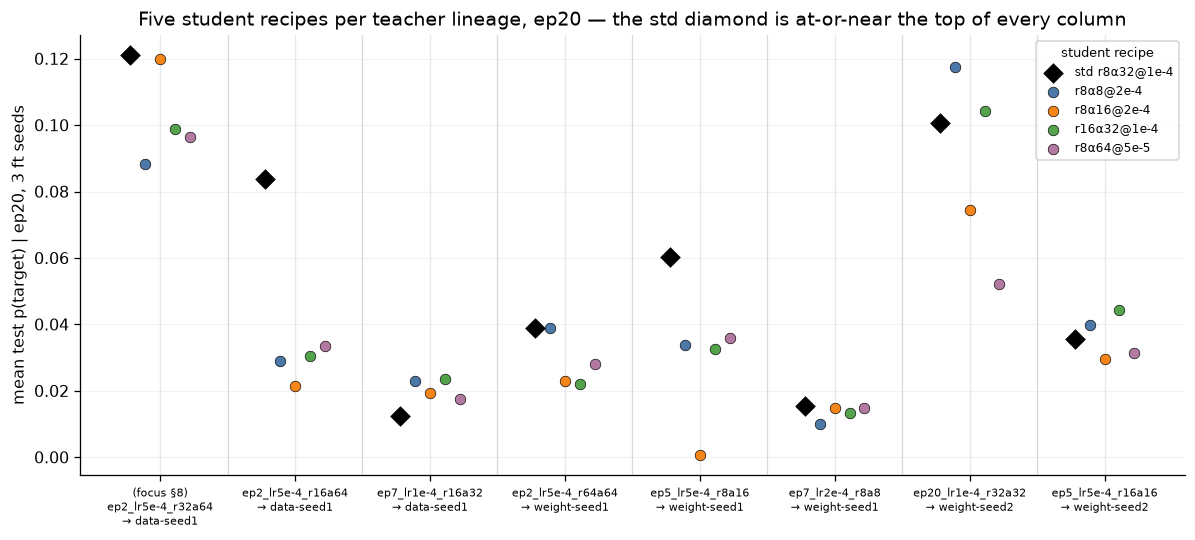

max gain of any gentle recipe over its lineage's own std (ep20): +0.017 — inside the ±0.06 noise band (§6)
dead ep20 menu cells (mean < 0.005): ep5_lr5e-4_r8a16 → weight-seed1 · r8α16@2e-4 = 0.0006
=> the std recipe stays the cross-init default; teacher lineage moves transfer far more than recipe choice


In [15]:
# One chart: each lineage's five recipes side by side at ep20. Black diamond = the std recipe;
# the four gentle recipes keep fixed colours (legend). If any gentle recipe beat std anywhere,
# its dot would sit clearly above the diamond in that column — none does.
RECIPE_COLORS = {RECIPE_ORDER[0]: "black", RECIPE_ORDER[1]: "#4c78a8", RECIPE_ORDER[2]: "#f58518",
                 RECIPE_ORDER[3]: "#54a24b", RECIPE_ORDER[4]: "#b279a2"}
d20 = menu_cells[menu_cells.ep.eq(20)]
fig, ax = plt.subplots(figsize=(10.5, 4.8))
for j, lab in enumerate(RECIPE_ORDER):
    g = d20[d20.recipe.eq(lab)].set_index("lineage").mean_test.reindex(LINEAGES)
    x = np.arange(len(LINEAGES)) + (j - 2) * .11
    std = lab == RECIPE_ORDER[0]
    ax.scatter(x, g.values, s=76 if std else 44, marker="D" if std else "o",
               color=RECIPE_COLORS[lab], edgecolor="k", lw=.4, zorder=4 if std else 3, label=lab)
for i in range(1, len(LINEAGES)):
    ax.axvline(i - .5, color=".85", lw=.8, zorder=1)
ax.set_xticks(range(len(LINEAGES)))
ax.set_xticklabels([("(focus §8)\n" if l == LINEAGES[0] else "") + l.replace(" → ", "\n→ ")
                    for l in LINEAGES], fontsize=7)
ax.set(ylabel="mean test p(target) | ep20, 3 ft seeds",
       title="Five student recipes per teacher lineage, ep20 — the std diamond is at-or-near the top of every column")
ax.grid(axis="y", alpha=.15)
ax.legend(fontsize=7.5, title="student recipe", title_fontsize=8, loc="upper right")
plt.tight_layout(); plt.show()

d = p20[RECIPE_ORDER[1:]].sub(p20[RECIPE_ORDER[0]], axis=0)
dead20 = d20[d20.mean_test.lt(.005) & ~d20.is_focus]
print(f"max gain of any gentle recipe over its lineage's own std (ep20): {d.max().max():+.3f} "
      "— inside the ±0.06 noise band (§6)")
print("dead ep20 menu cells (mean < 0.005):",
      "; ".join(f"{t.lineage} · {t.recipe} = {t.mean_test:.4f}" for t in dead20.itertuples()) or "none")
print("=> the std recipe stays the cross-init default; teacher lineage moves transfer far more than recipe choice")


### Interpretation checklist

- Every number here is **cross-initialization** transfer into a re-seeded PolyPythia — the same-init reference lives in the cross-seed notebook, at ~2–6× these levels.
- The two aggression knobs (lr, LoRA α) collapse to **one product, lr × α** (§8): cells survive at lr×α ≤ ~3e-3 and die by lr×α ≳ 1e-2, with a mixed boundary near 6e-3 (lower lr / larger rank can still rescue). This *supersedes* the earlier "lr ≥ 2e-4 ⇒ dead" rule — lr 2e-4 at small α (r8α16) is the top cell (0.120), and r8α64 is dead at lr 5e-4 but alive (0.096) at lr 5e-5. Do not re-test the high-`lr × α` corner; do explore low-α at lr 2e-4.
- Within the live region (lr × α ≲ 3e-3), capacity at gentle scale helps only modestly — most recipes land within seed noise of the standard recipe. The seed-1 r16α32 "win" (0.168) did not replicate (mean 0.099 vs baseline 0.121).
- Seed spread on live cells is large (±0.06); only replicated contrasts count. The exploration puts 3 seeds on the frontier, the ep40 rung, the §8 lr×α control, and all of §10. Prefer *reliable* winners (all seeds off zero): r8α64@lr5e-5 (0.096), r8α8@lr2e-4 (0.088) over high-variance ones (r8α16 spans 0.002–0.240 at the focus, and is dead 3-for-3 on one §10 lineage).
- Dose (epochs) is the one axis that has consistently paid: ep20 ≫ ep5 at matched HP throughout — §10 confirms this on every lineage with std ep20 ≥ 0.03.
- The lr×α law's cross-teacher status is now **tested** (§10, seven lineages × three bases): the *safety* half generalizes (69/70 gentle cells alive; one true death at gentle lr×α, so necessary-not-sufficient), the *ranking* half does not — no gentle recipe beats a lineage's own std baseline by more than +0.017. Treat the std recipe as the cross-init default; teacher lineage choice moves transfer far more than student HP within the safe region.
- `off_topic` was never scored for these students; specificity claims need that backfill first.